<a href="https://www.kaggle.com/code/lalit7881/historical-bakery-sales-analysis-eda?scriptVersionId=360636769" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv
/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset_Copy.xlsx


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv")

In [3]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [4]:
df.tail()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
19316,ORD06574,CUST0206,16,Female,Student,Yes,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST01,2,1,1,1,50.0,18.85,4
19317,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST02,2,1,1,1,50.0,166.09,4
19318,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,...,Room Temperature,High,ST02,2,1,1,1,50.0,69.18,4
19319,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,...,Room Temperature,Very High,ST01,6,5,1,1,16.7,64.85,3
19320,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST01,2,1,1,1,50.0,19.75,3


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

In [6]:
df.describe()

,Customer_Age,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
count,19321.000000,19321.000000,19321.000000,19321.000000,19321.00000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000
mean,35.541846,2023.508100,6.559184,15.871901,12.86481,26.988127,2.226955,87.263624,49.275521,4.345541,83.372033,139.268467,61.117333,4.221469,3.046788,1.174680,1.131101,34.118715,59.196602,3.827700
std,13.733832,0.499947,3.478048,8.767930,3.94044,8.813511,1.782968,110.481951,65.969024,6.794384,105.762887,157.772593,103.611553,3.635227,3.038092,0.783283,0.752667,12.734206,65.238370,0.948831
min,16.000000,2023.000000,1.000000,1.000000,7.00000,8.100000,1.000000,7.600000,3.270000,0.000000,5.680000,13.120000,1.000000,2.000000,1.000000,1.000000,1.000000,4.200000,-0.550000,1.000000
25%,25.000000,2023.000000,4.000000,8.000000,9.00000,21.200000,1.000000,31.020000,16.900000,0.000000,30.400000,52.120000,3.000000,2.000000,1.000000,1.000000,1.000000,25.000000,20.690000,3.000000
50%,34.000000,2024.000000,7.000000,16.000000,12.00000,27.700000,2.000000,45.090000,23.640000,0.000000,42.660000,82.800000,5.000000,3.000000,2.000000,1.000000,1.000000,33.300000,36.760000,4.000000
75%,45.000000,2024.000000,10.000000,24.000000,17.00000,33.200000,3.000000,76.650000,52.640000,7.500000,72.030000,146.540000,82.000000,5.000000,4.000000,1.000000,1.000000,50.000000,65.920000,4.000000
max,73.000000,2024.000000,12.000000,31.000000,21.00000,44.900000,20.000000,472.420000,296.280000,30.000000,472.420000,1885.960000,729.000000,49.000000,37.000000,16.000000,20.000000,50.000000,767.600000,5.000000


In [7]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
Customer_Segment           0
Loyalty_Member             0
Date                       0
Year                       0
Month                      0
Day                        0
Day_of_Week                0
Weekend                    0
Hour                       0
Time                       0
Season                     0
Festival               16006
Weather                    0
Temperature                0
Product                    0
Category                   0
Quantity                   0
Unit_Price                 0
Cost_Price                 0
Discount_Percentage        0
Selling_Price              0
Total_Bill                 0
Payment_Method             0
Promotion_Applied          0
Promotion_Type         13826
Shelf_Life_Days            0
Storage_Type               0
Perishability              0
Store_ID                   0
Units_Produced             0
Units_Sold    

In [8]:

df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

Order_ID                object
Customer_ID             object
Customer_Age             int64
Customer_Gender         object
Customer_Segment        object
Loyalty_Member          object
Date                    object
Year                     int64
Month                    int64
Day                      int64
Day_of_Week             object
Weekend                 object
Hour                     int64
Time                    object
Season                  object
Festival                object
Weather                 object
Temperature            float64
Product                 object
Category                object
Quantity                 int64
Unit_Price             float64
Cost_Price             float64
Discount_Percentage    float64
Selling_Price          float64
Total_Bill             float64
Payment_Method          object
Promotion_Applied       object
Promotion_Type          object
Shelf_Life_Days          int64
Storage_Type            object
Perishability           object
Store_ID

In [10]:
df.shape

(19321, 40)

In [11]:
df.nunique()

Order_ID                6576
Customer_ID              500
Customer_Age              57
Customer_Gender            3
Customer_Segment           4
Loyalty_Member             2
Date                     731
Year                       2
Month                     12
Day                       31
Day_of_Week                7
Weekend                    2
Hour                      15
Time                     872
Season                     4
Festival                   9
Weather                    6
Temperature              305
Product                   35
Category                   7
Quantity                  17
Unit_Price              7711
Cost_Price              6232
Discount_Percentage      292
Selling_Price           8657
Total_Bill             11349
Payment_Method             4
Promotion_Applied          2
Promotion_Type             5
Shelf_Life_Days          498
Storage_Type               3
Perishability              4
Store_ID                   3
Units_Produced            45
Units_Sold    

In [12]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender',
       'Customer_Segment', 'Loyalty_Member', 'Date', 'Year', 'Month', 'Day',
       'Day_of_Week', 'Weekend', 'Hour', 'Time', 'Season', 'Festival',
       'Weather', 'Temperature', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price',
       'Total_Bill', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type',
       'Shelf_Life_Days', 'Storage_Type', 'Perishability', 'Store_ID',
       'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available',
       'Waste_Pct', 'Profit', 'Customer_Rating'],
      dtype='object')

## EDA

RETAIL SALES, CUSTOMER & INVENTORY DATA ANALYSIS

Dataset Shape: (19321, 40)

Column Names:
['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'Customer_Segment', 'Loyalty_Member', 'Date', 'Year', 'Month', 'Day', 'Day_of_Week', 'Weekend', 'Hour', 'Time', 'Season', 'Festival', 'Weather', 'Temperature', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type', 'Shelf_Life_Days', 'Storage_Type', 'Perishability', 'Store_ID', 'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating']

First 5 Rows:


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival      

,Missing_Values
Festival,16006
Promotion_Type,13826



Duplicate Rows: 0

Numeric Columns: ['Customer_Age', 'Year', 'Month', 'Day', 'Hour', 'Temperature', 'Quantity', 'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill', 'Shelf_Life_Days', 'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating']

Categorical Columns: ['Order_ID', 'Customer_ID', 'Customer_Gender', 'Customer_Segment', 'Loyalty_Member', 'Day_of_Week', 'Weekend', 'Time', 'Season', 'Festival', 'Weather', 'Product', 'Category', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type', 'Storage_Type', 'Perishability', 'Store_ID']


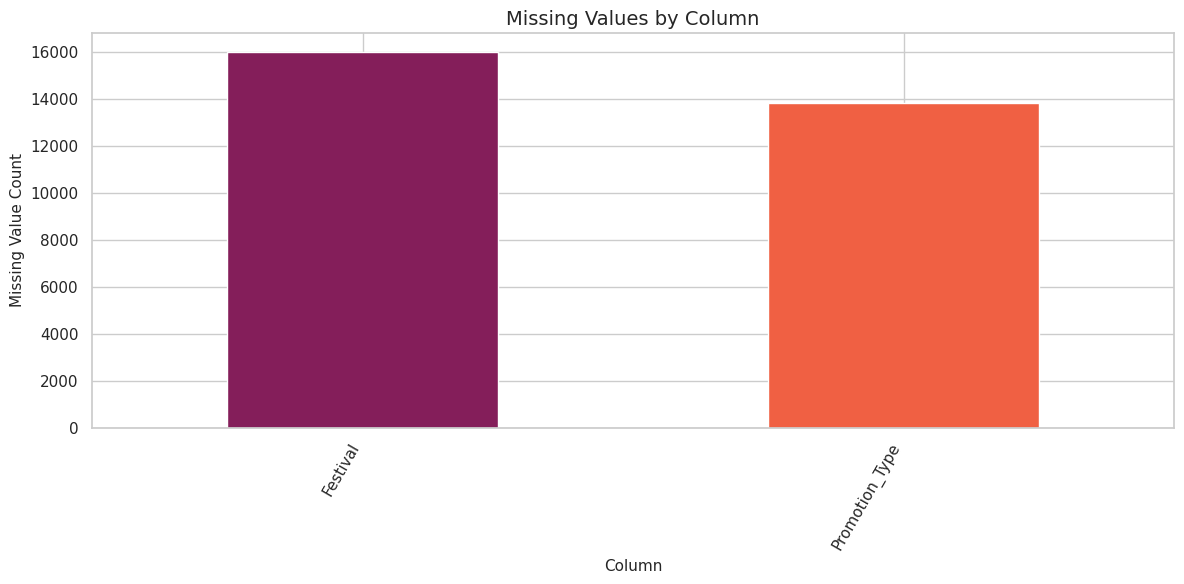

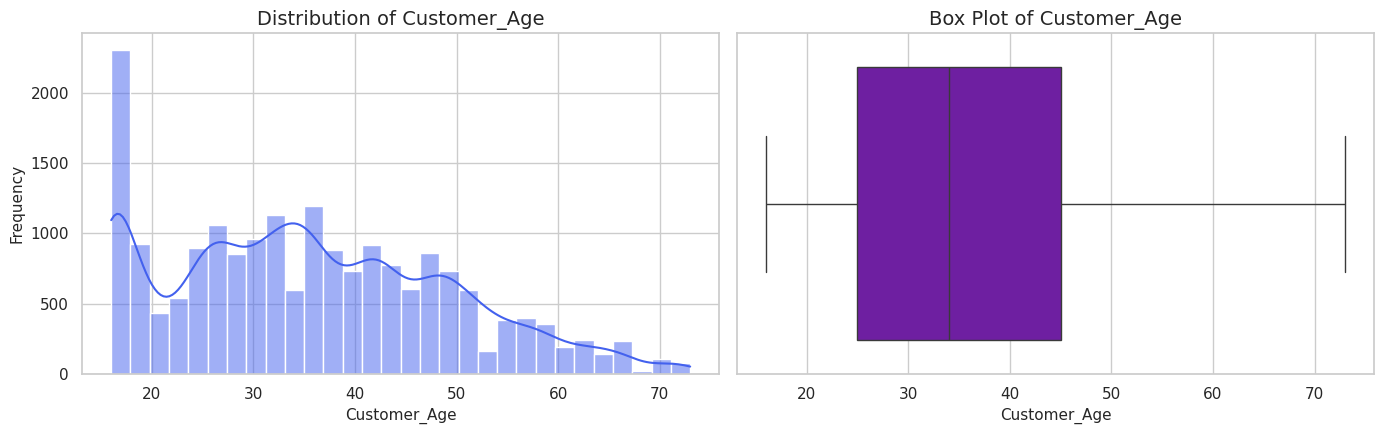

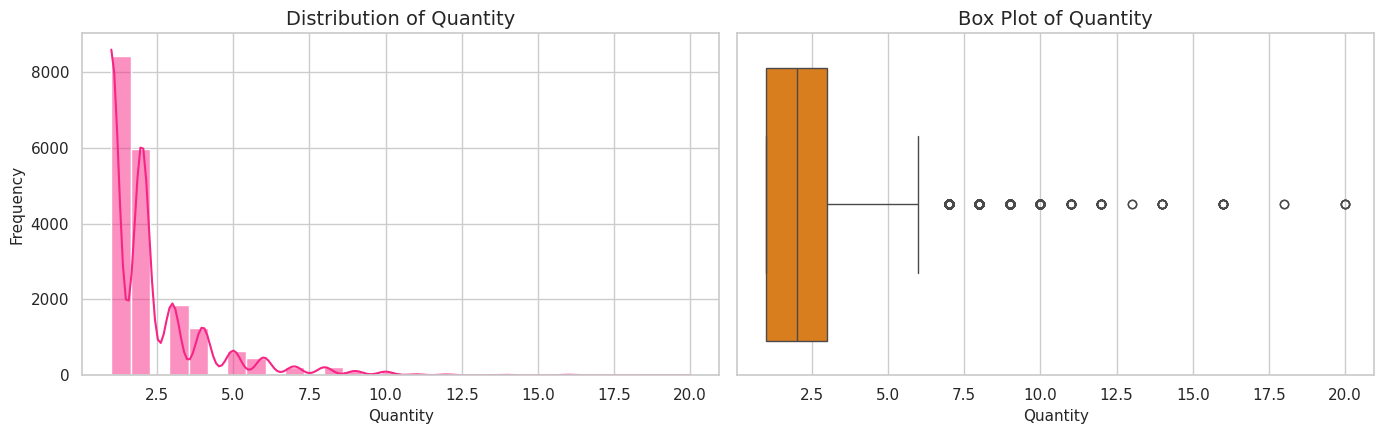

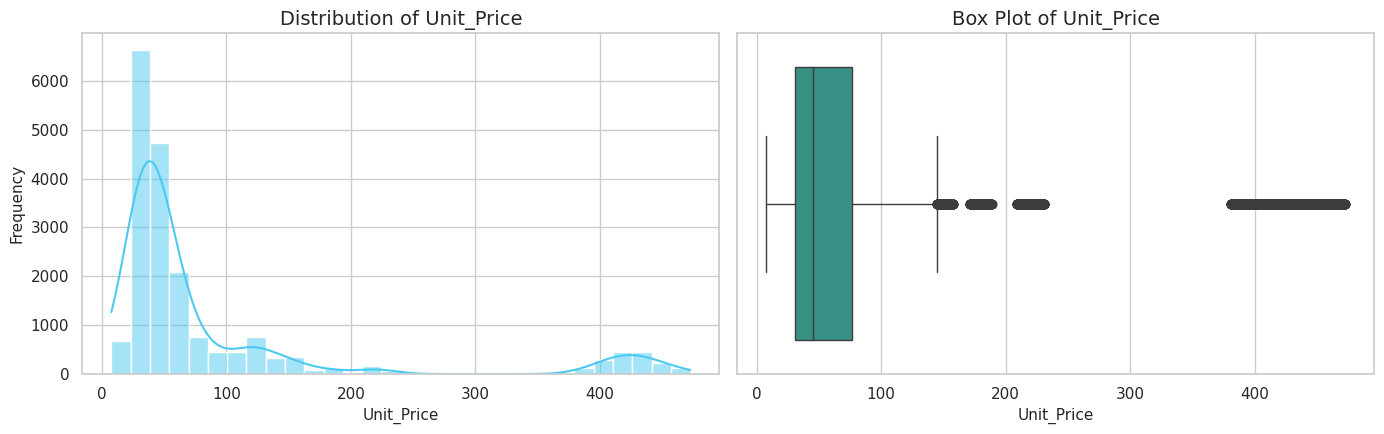

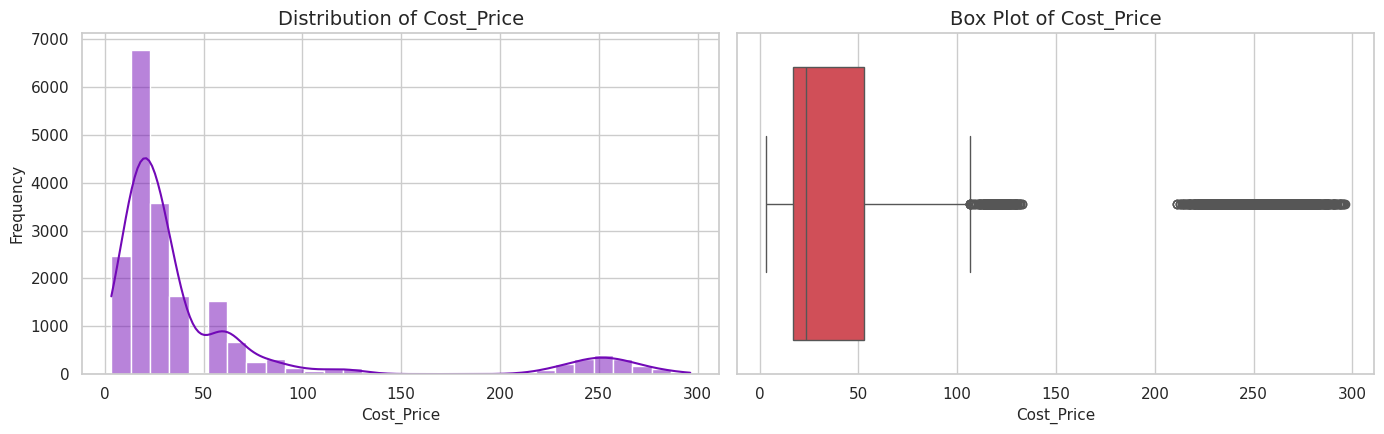

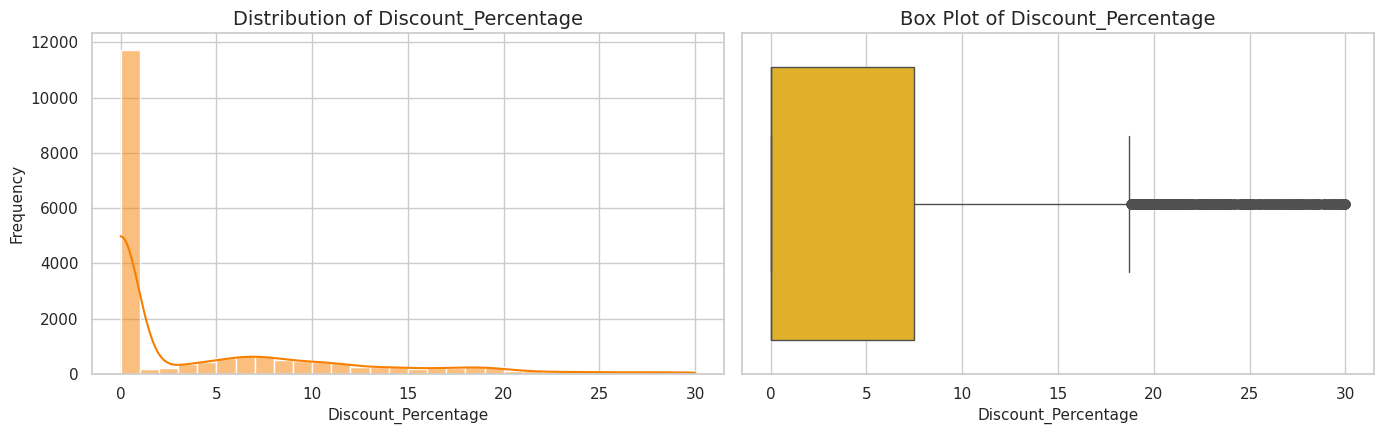

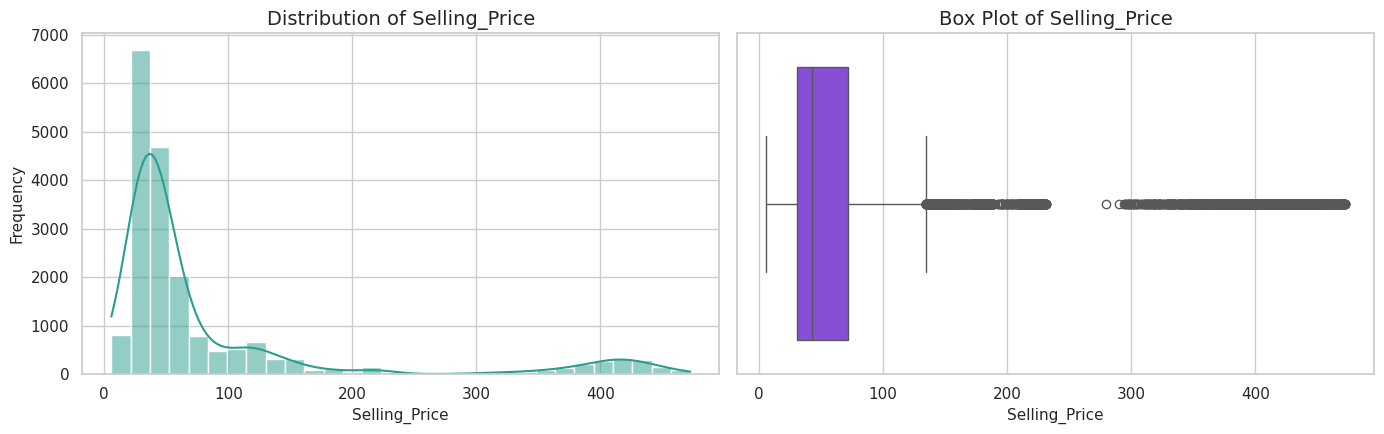

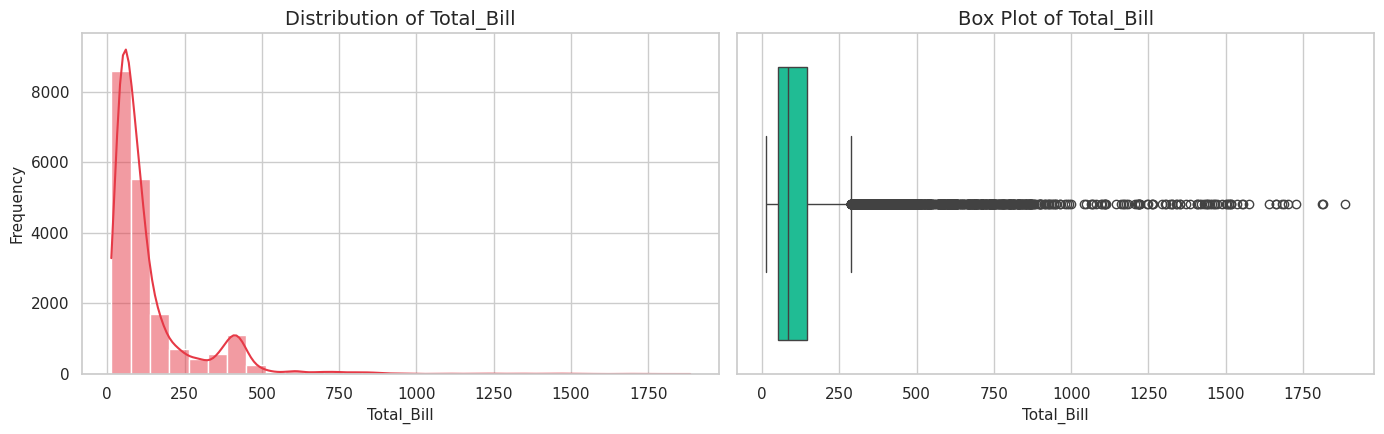

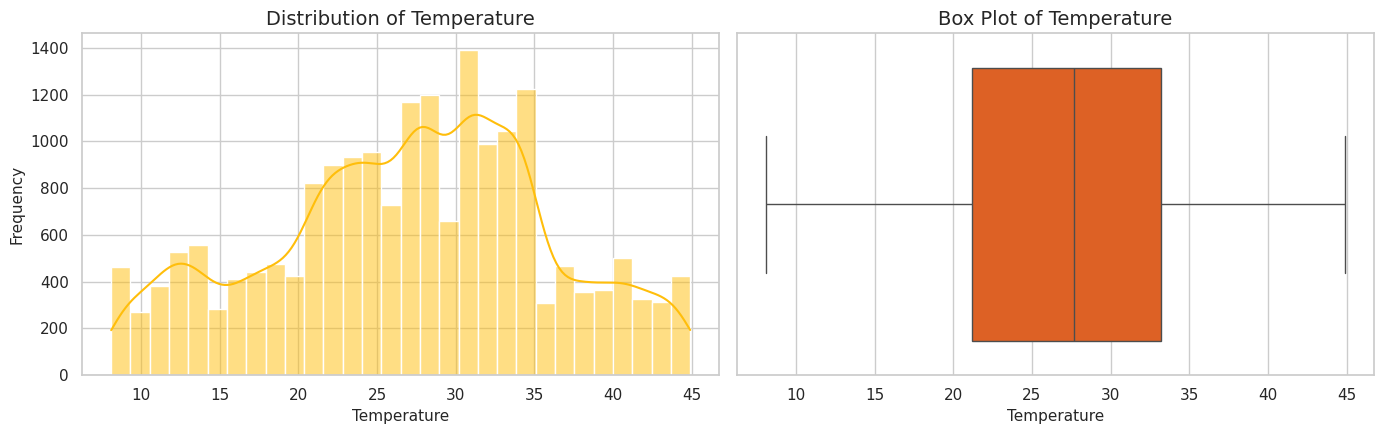

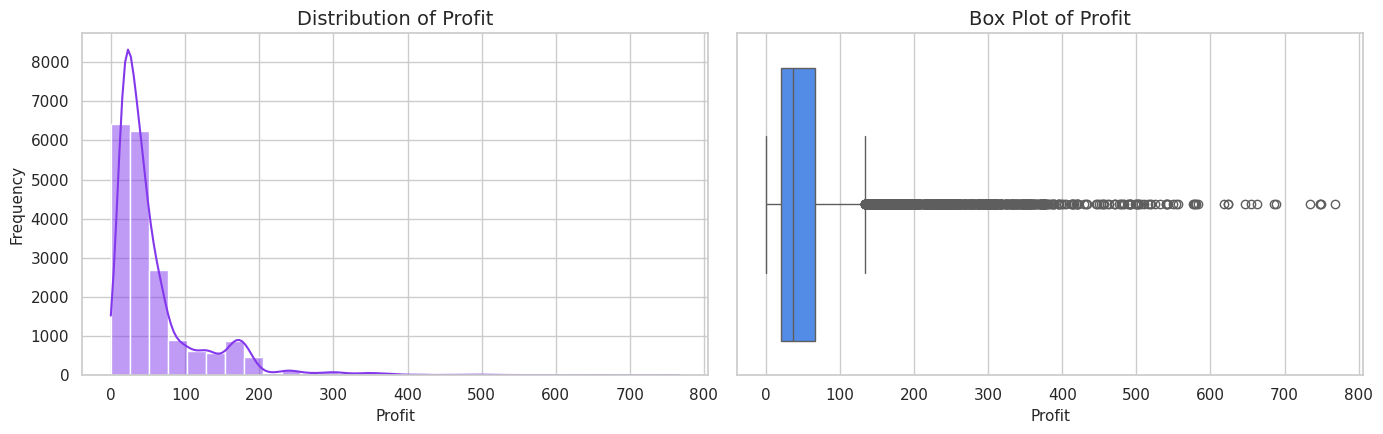

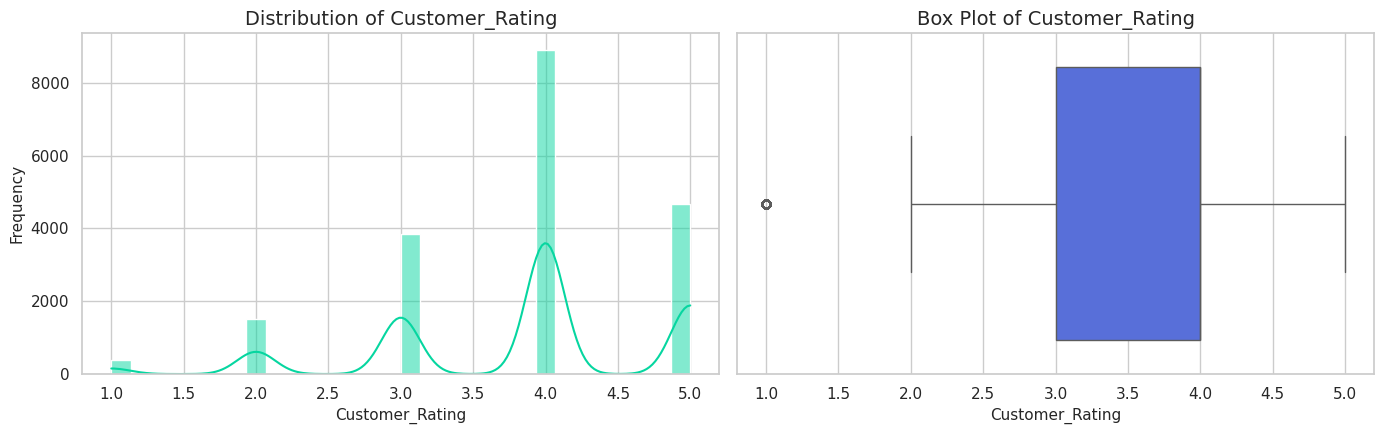

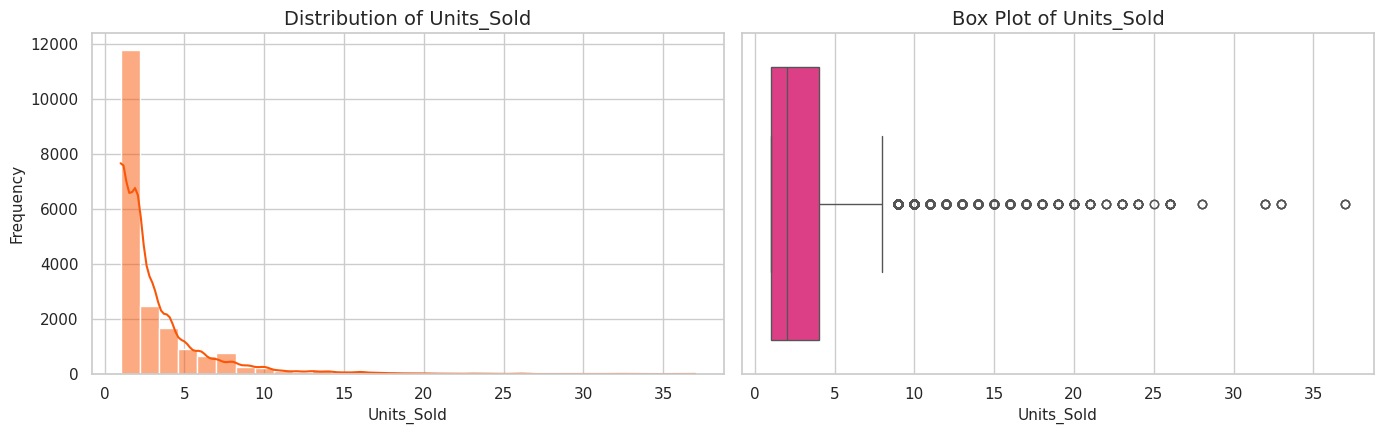

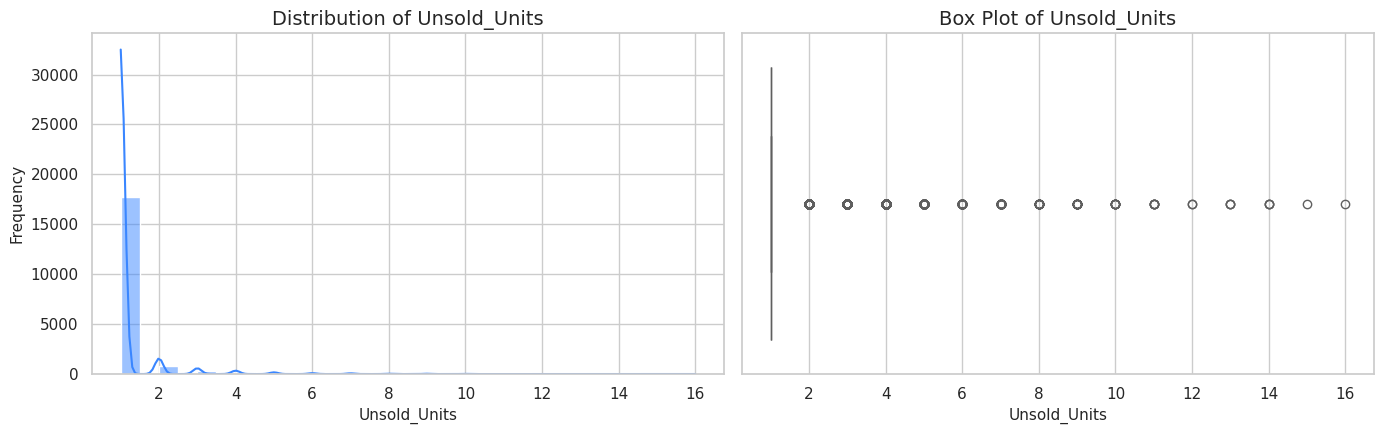

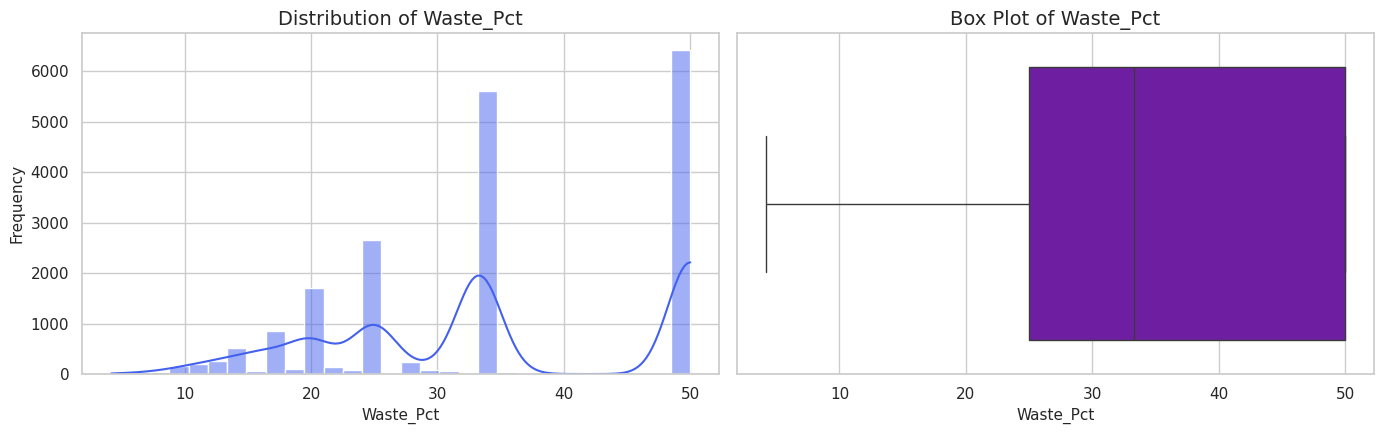

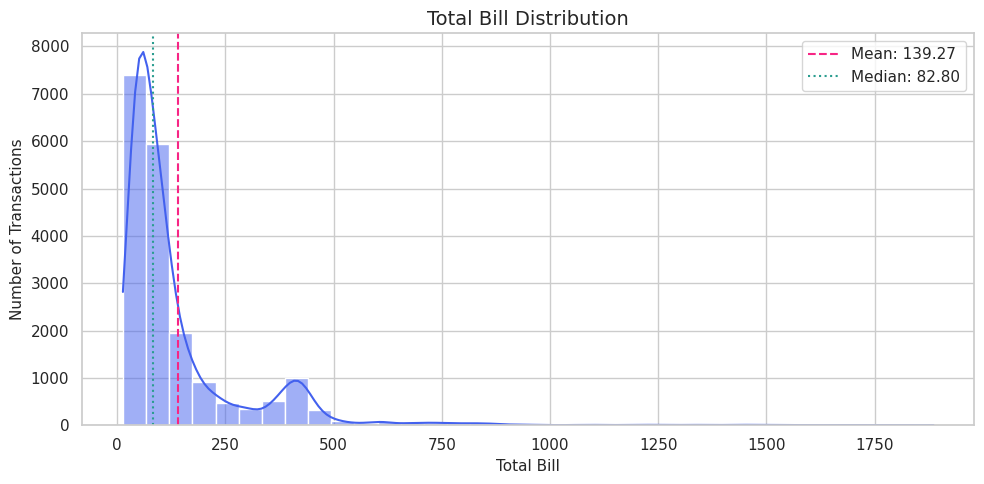


Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
Quantity,19321.0,2.23,1.78,1.00,1.00,2.00,3.00,20.00
Selling_Price,19321.0,83.37,105.76,5.68,30.40,42.66,72.03,472.42
Total_Bill,19321.0,139.27,157.77,13.12,52.12,82.80,146.54,1885.96
Profit,19321.0,59.20,65.24,-0.55,20.69,36.76,65.92,767.60
Units_Sold,19321.0,3.05,3.04,1.00,1.00,2.00,4.00,37.00
Unsold_Units,19321.0,1.17,0.78,1.00,1.00,1.00,1.00,16.00
Stock_Available,19321.0,1.13,0.75,1.00,1.00,1.00,1.00,20.00
Waste_Pct,19321.0,34.12,12.73,4.20,25.00,33.30,50.00,50.00
Customer_Rating,19321.0,3.83,0.95,1.00,3.00,4.00,4.00,5.00


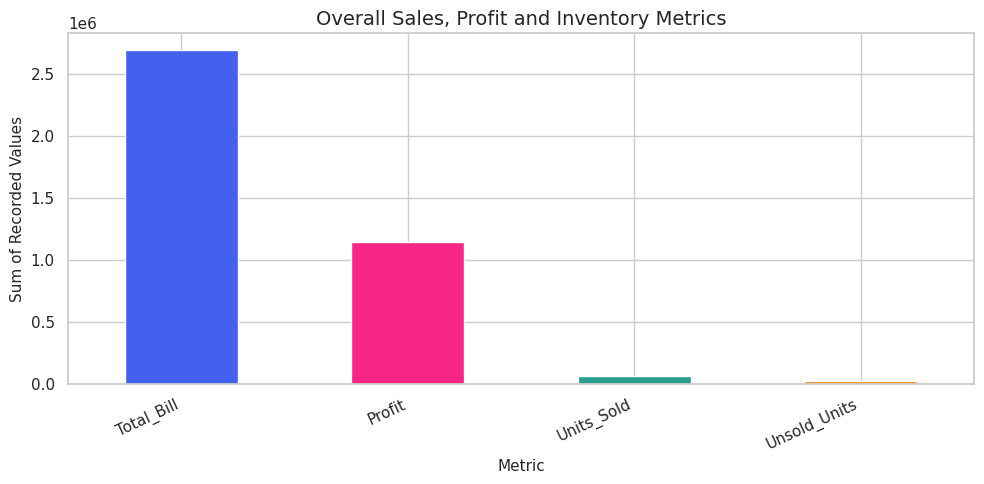

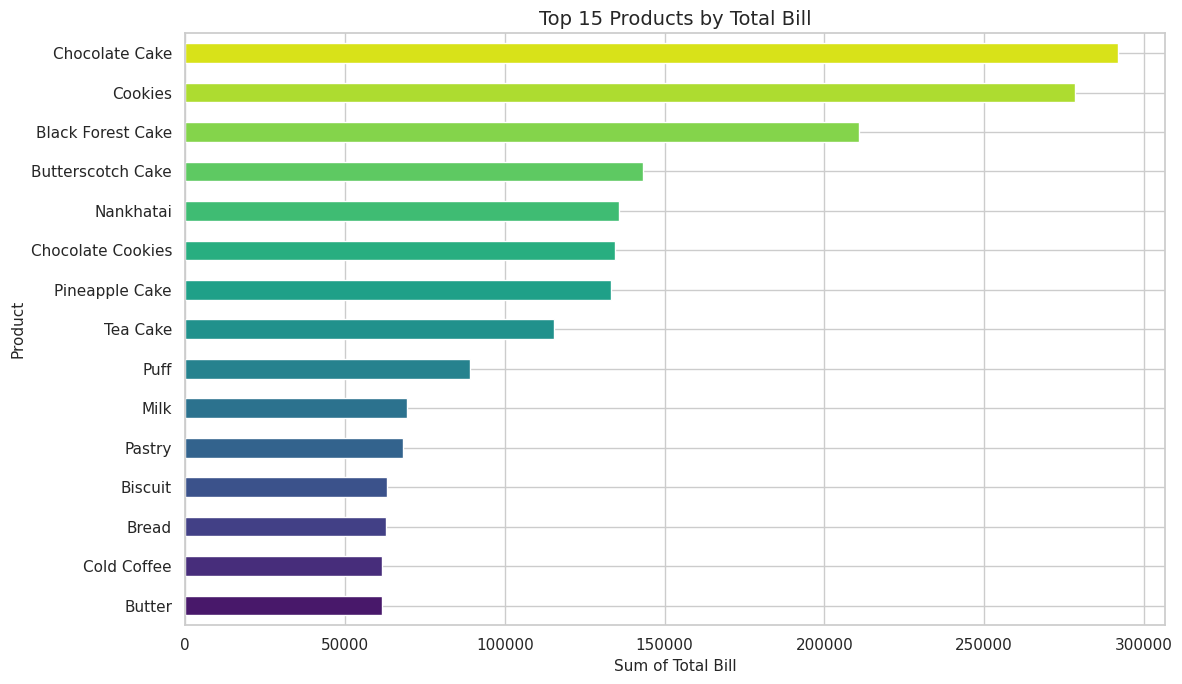

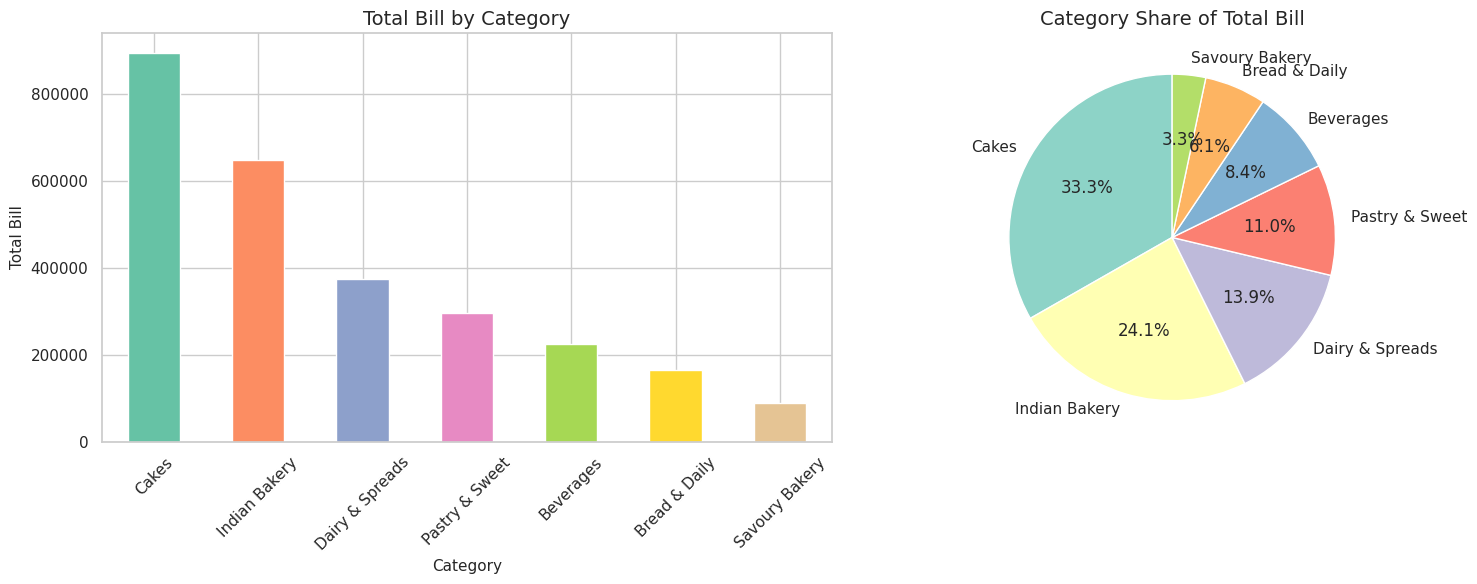

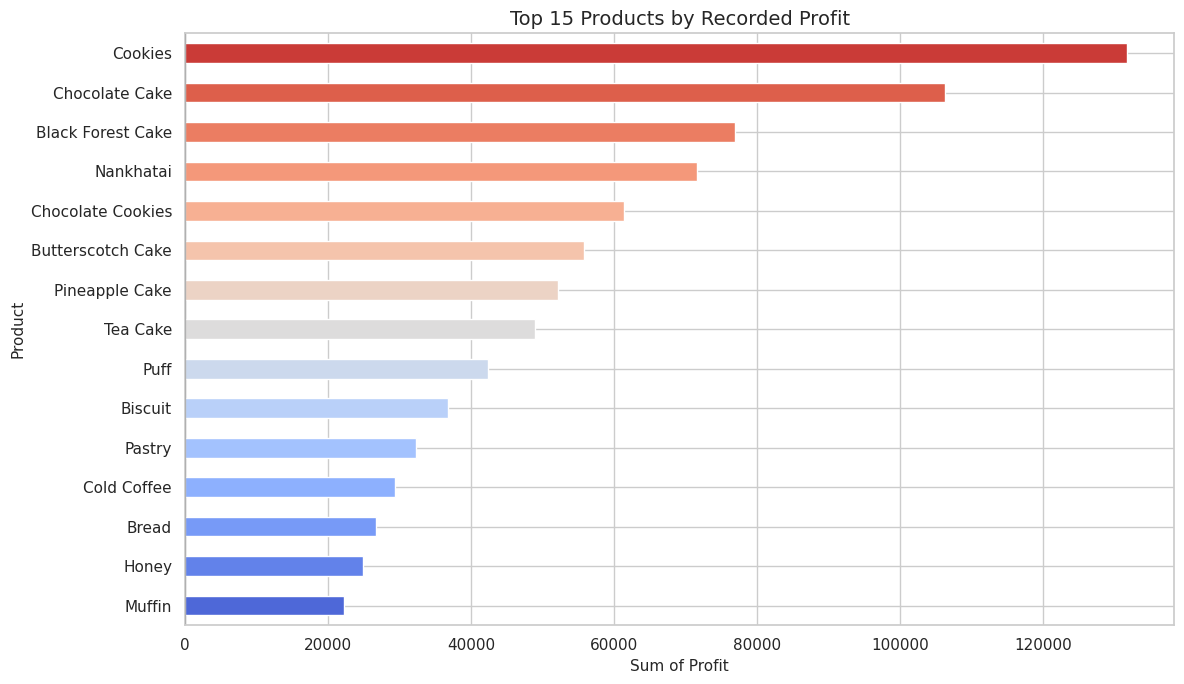

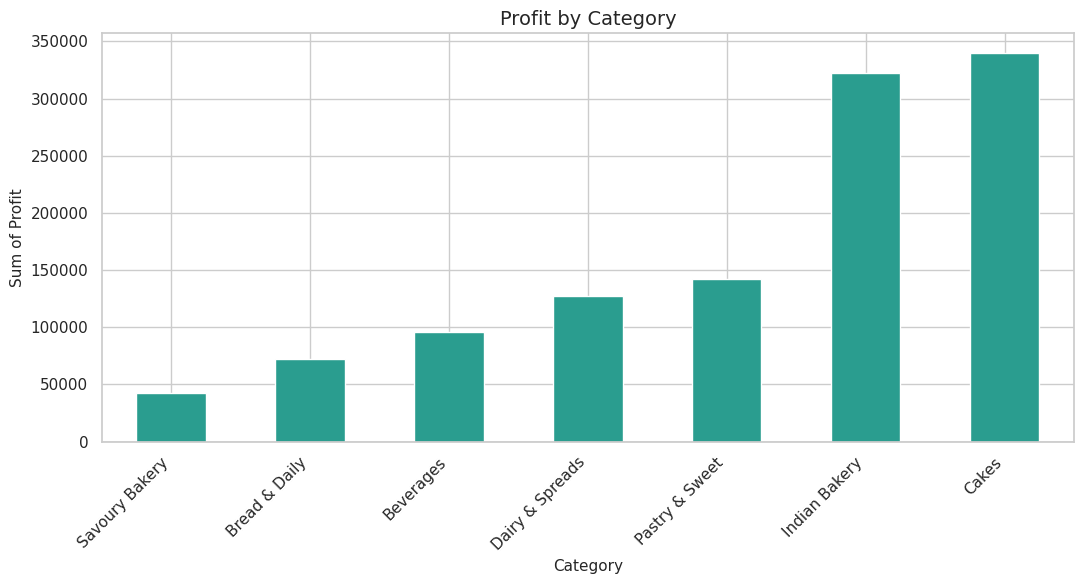

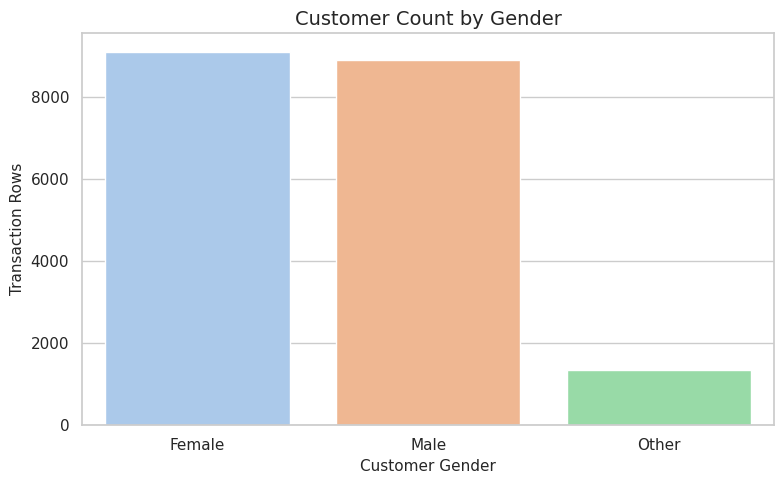

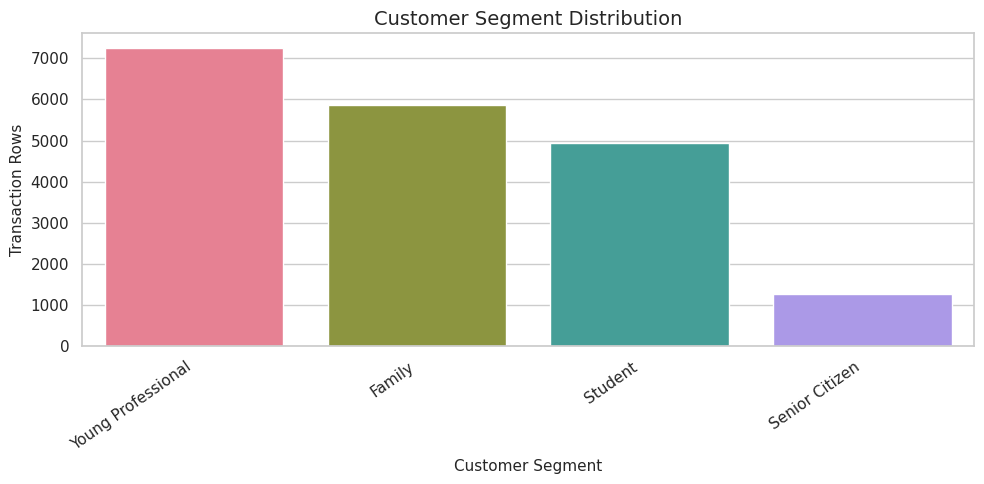

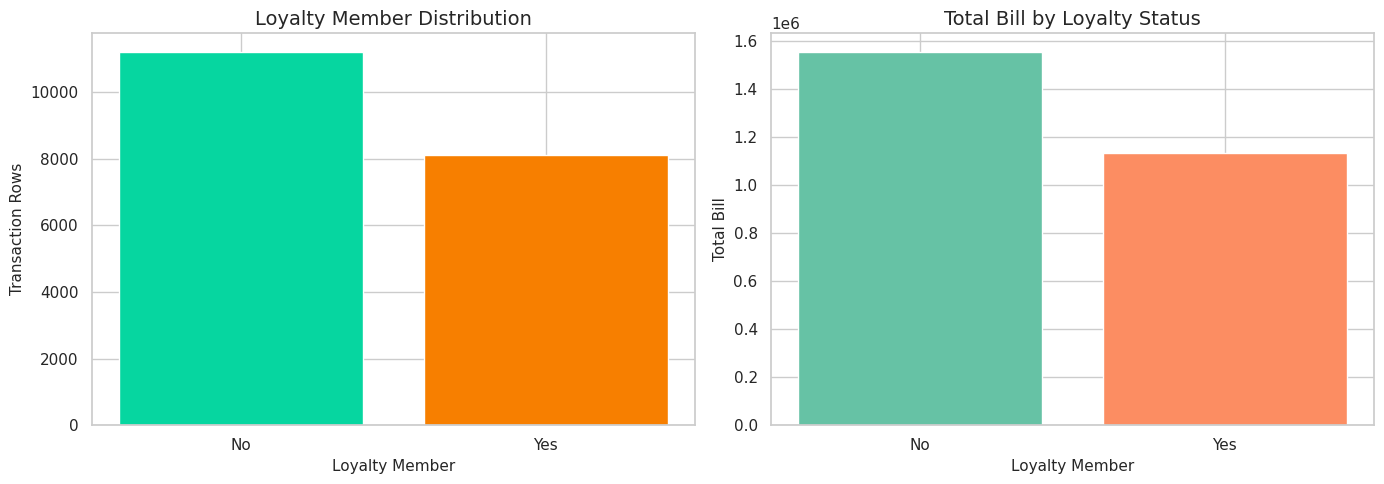

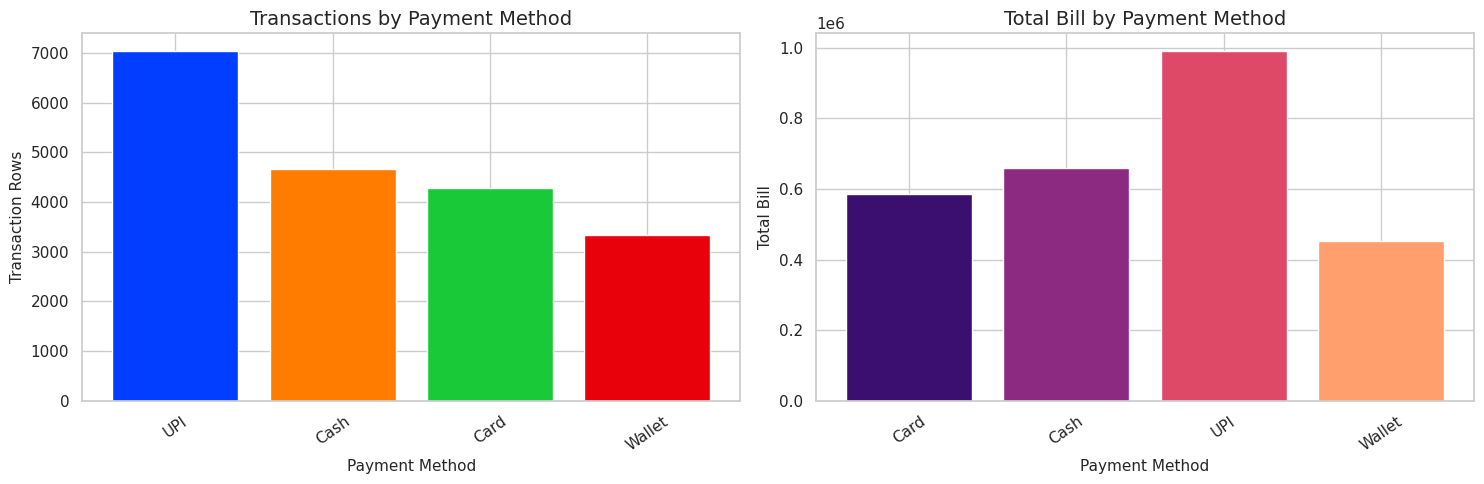

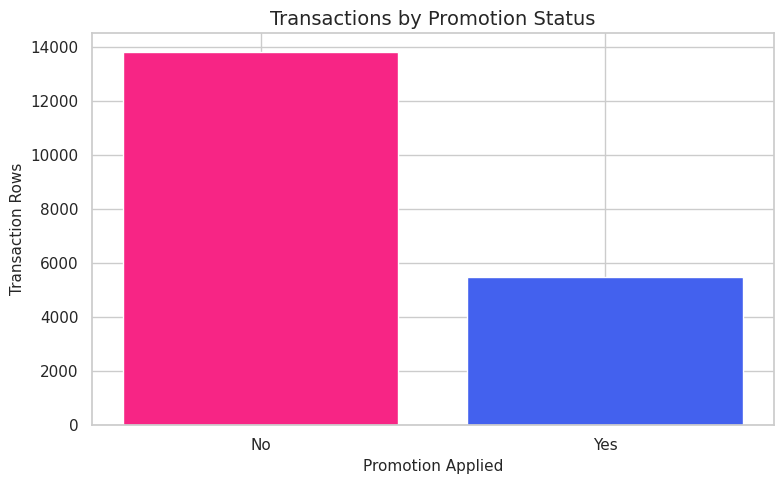

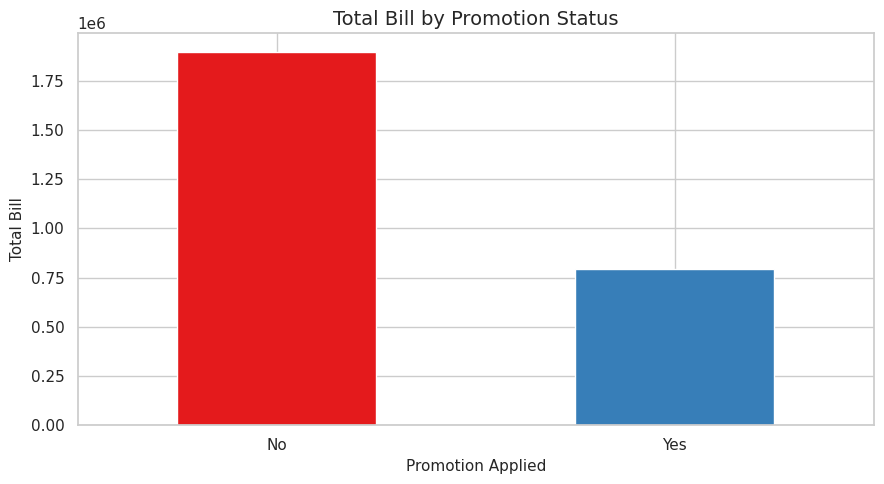

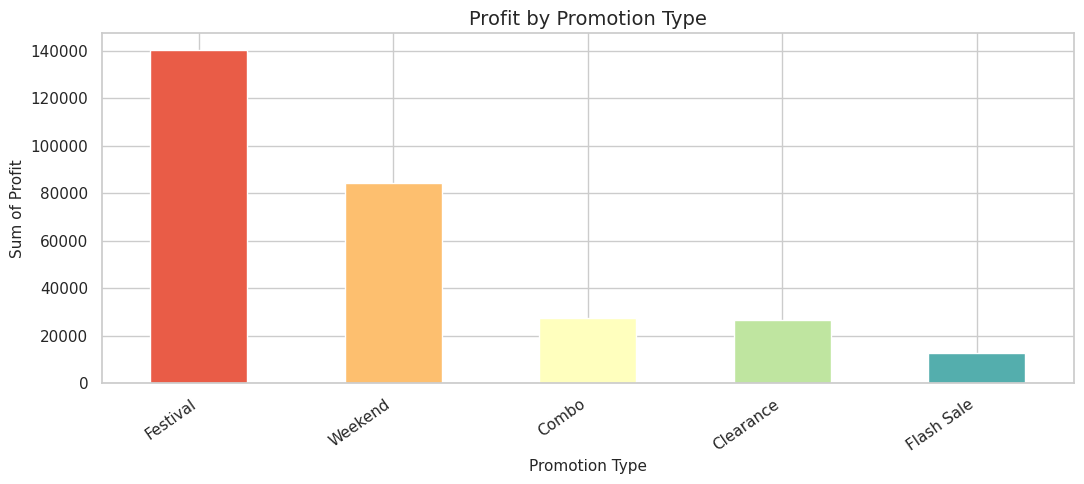

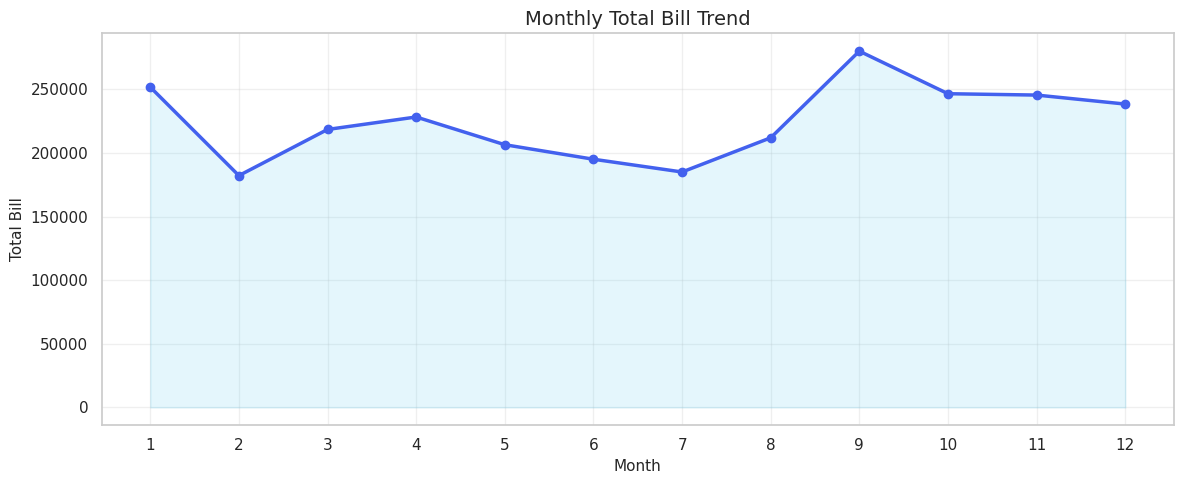

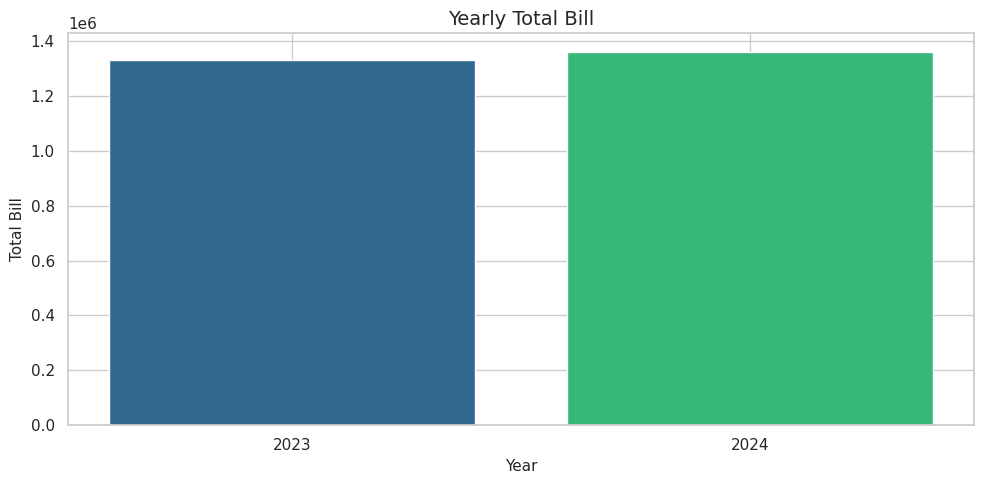

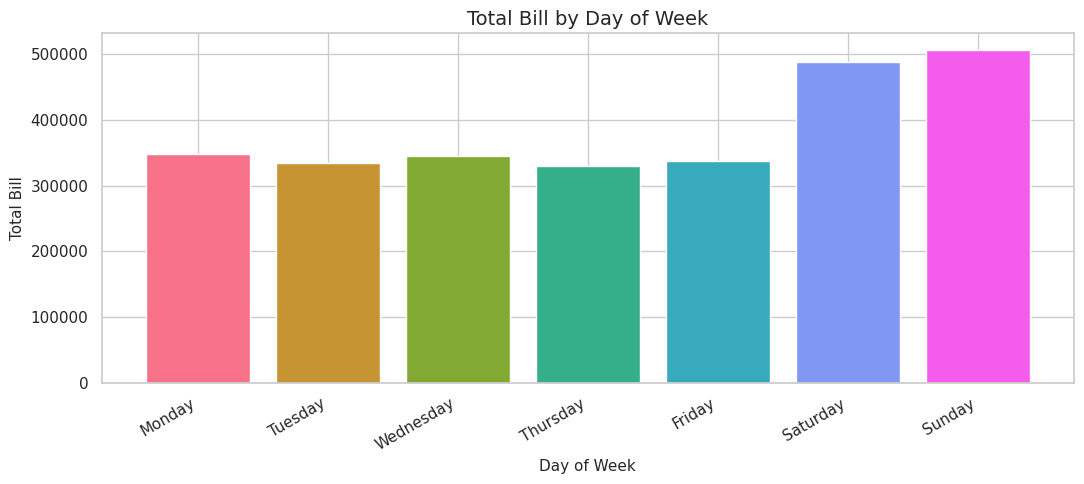

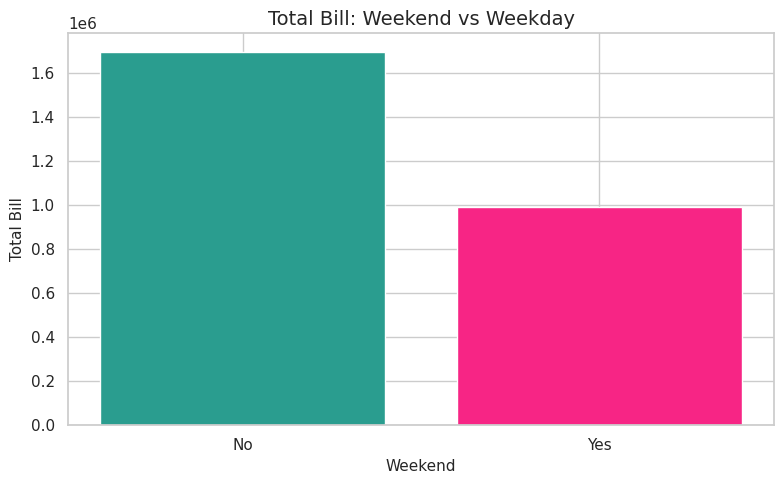

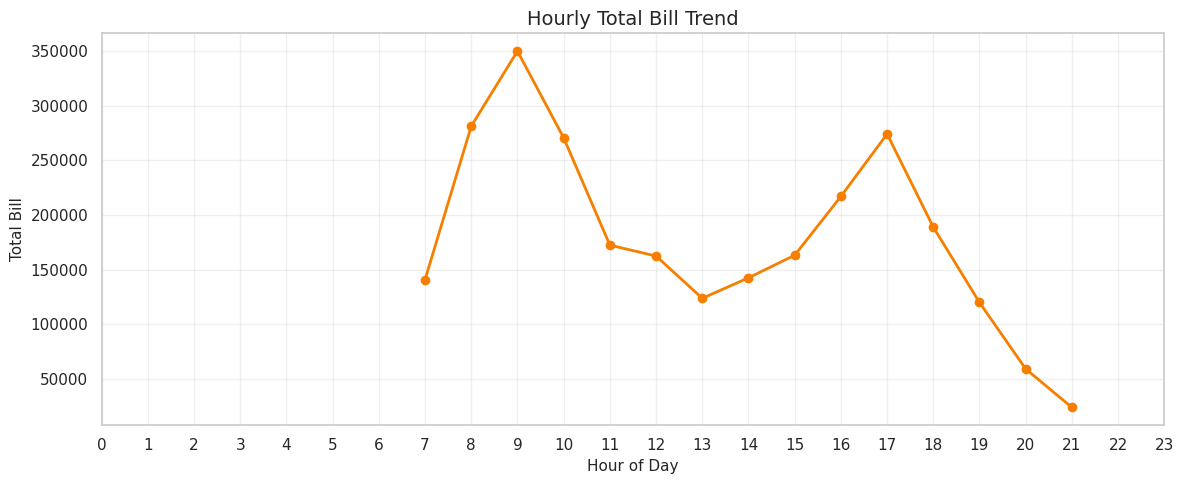

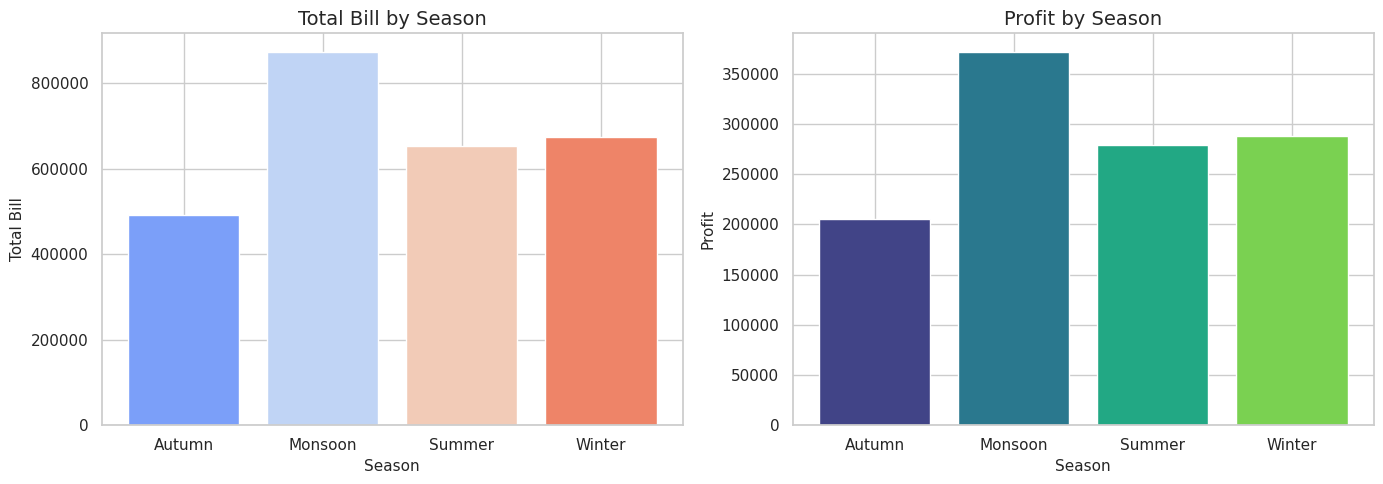

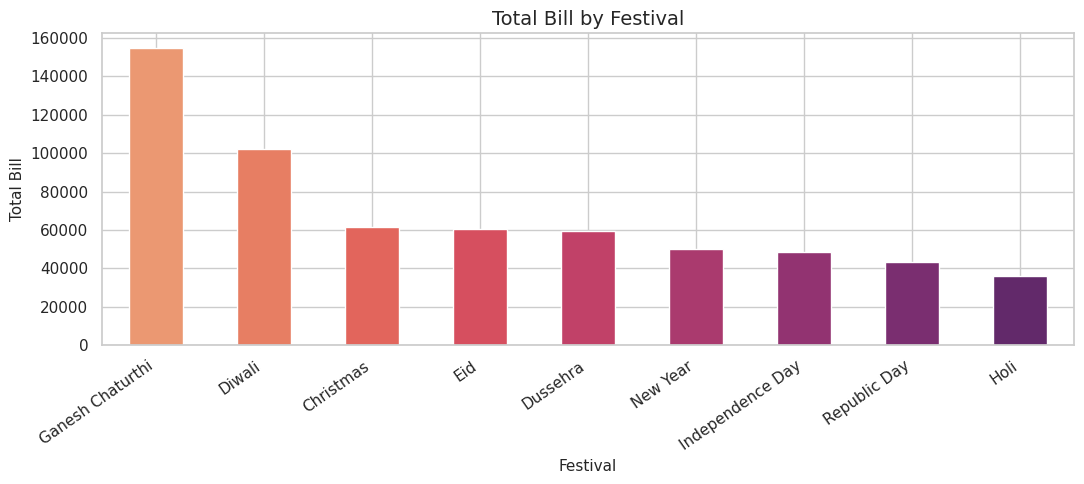

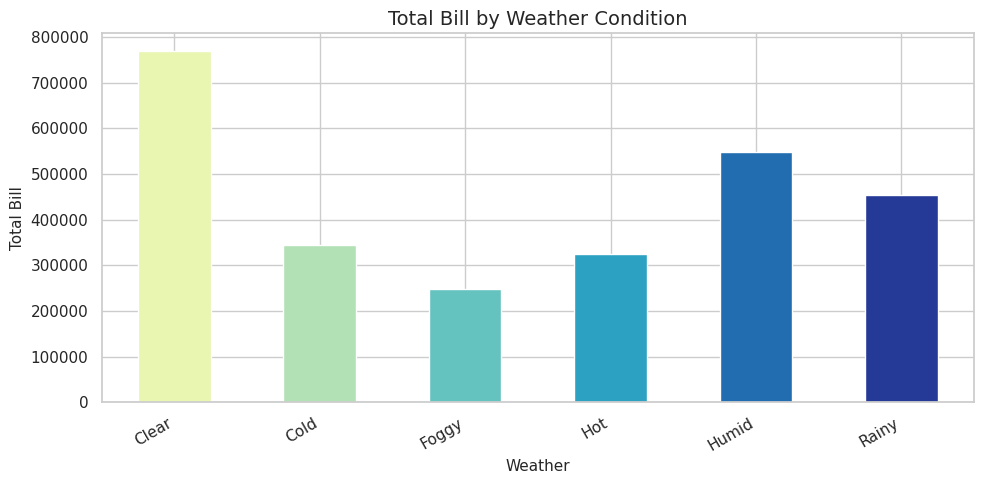

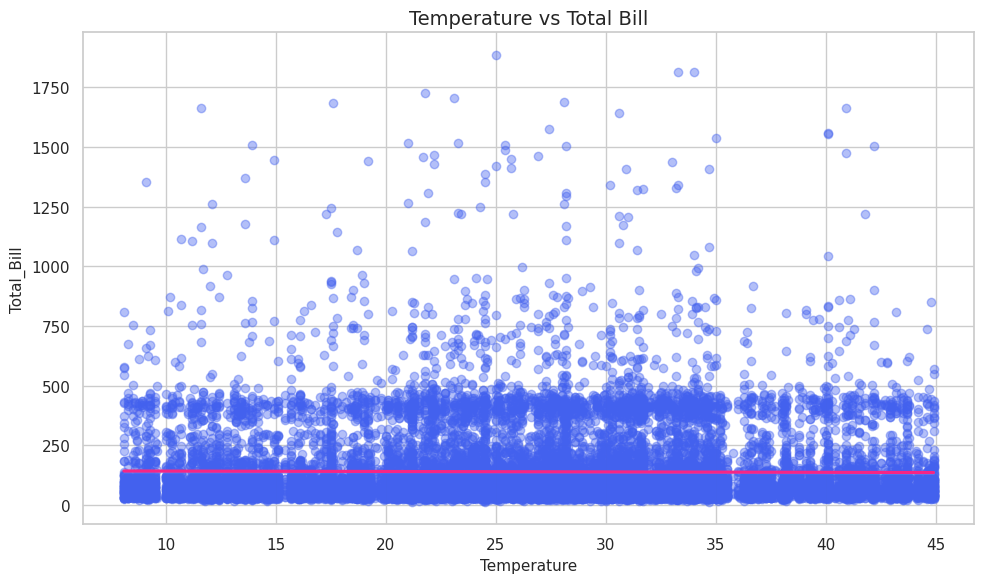

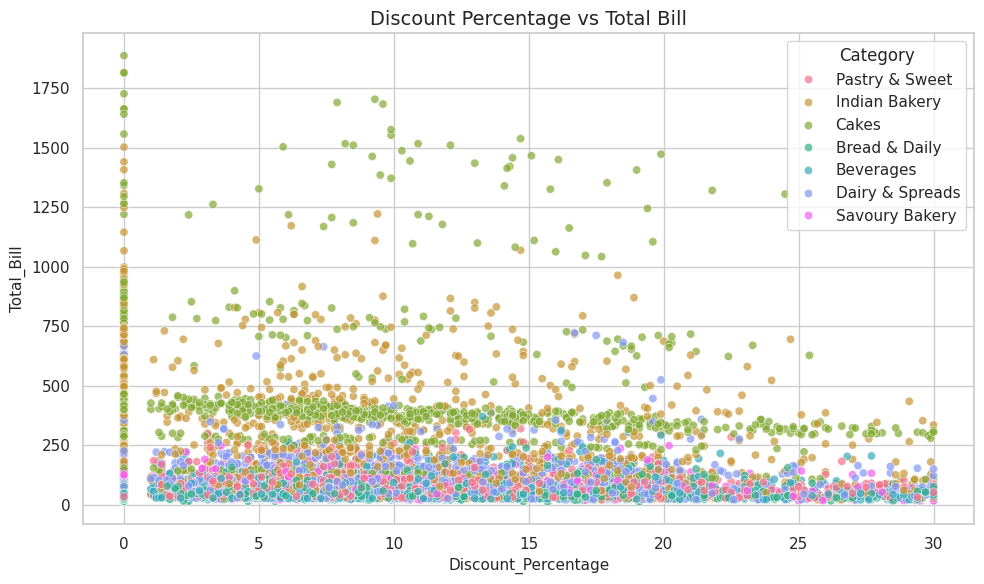

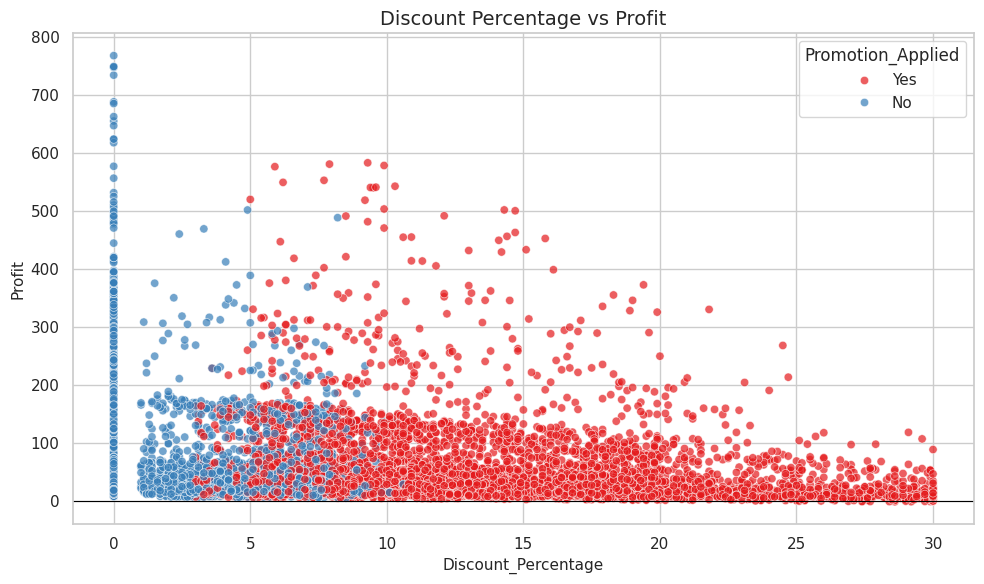

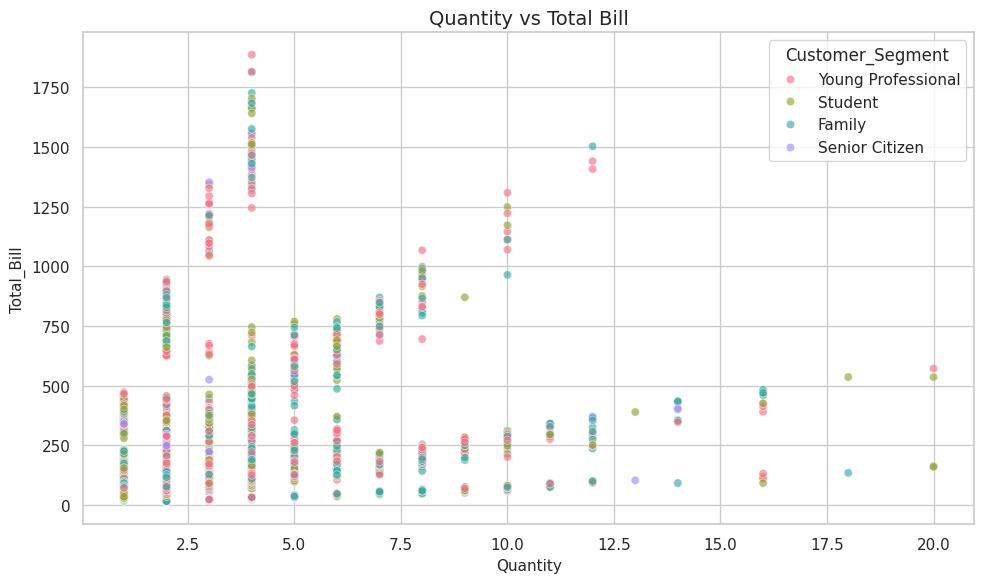

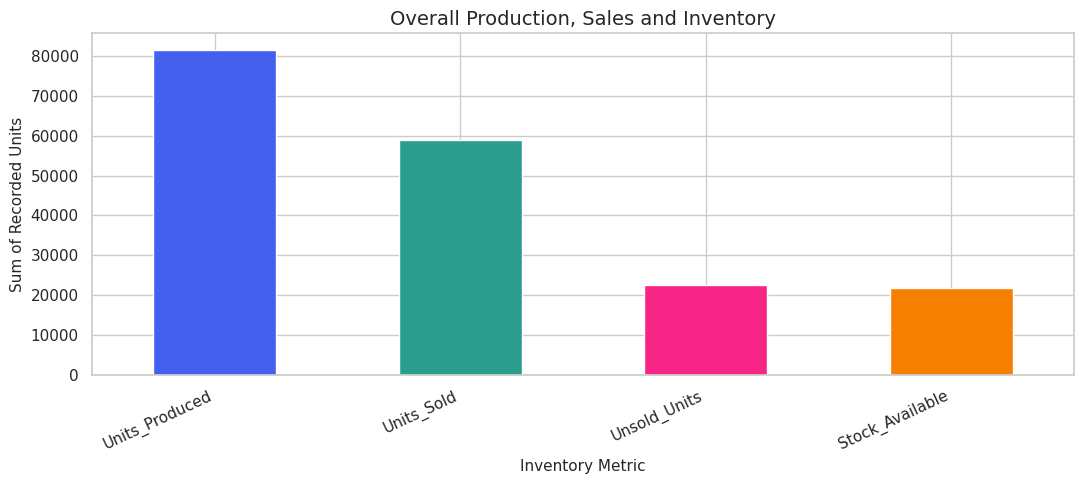

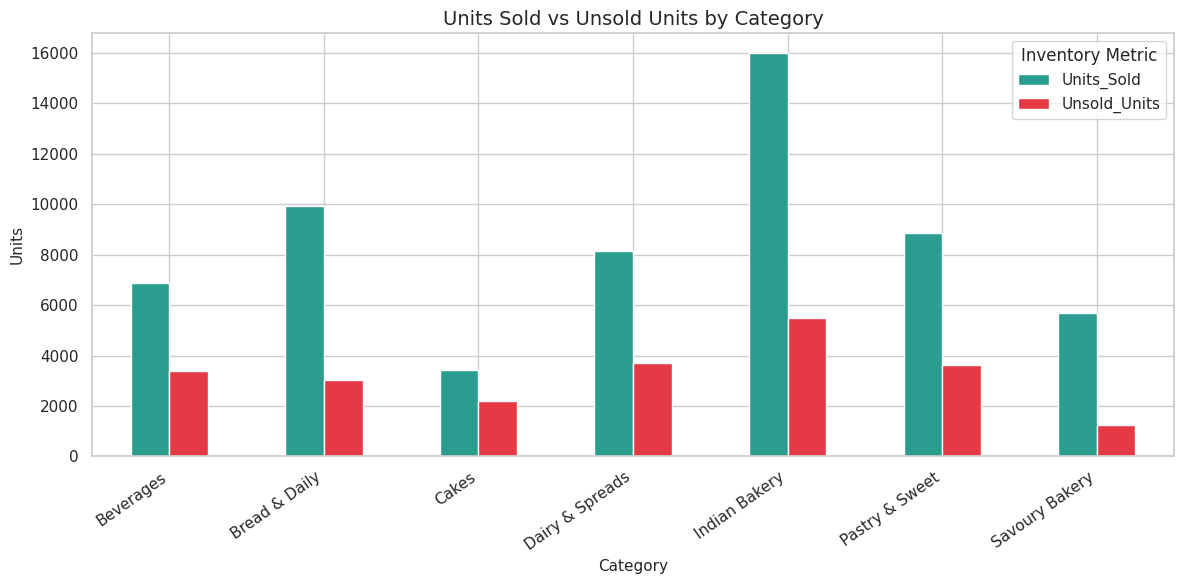

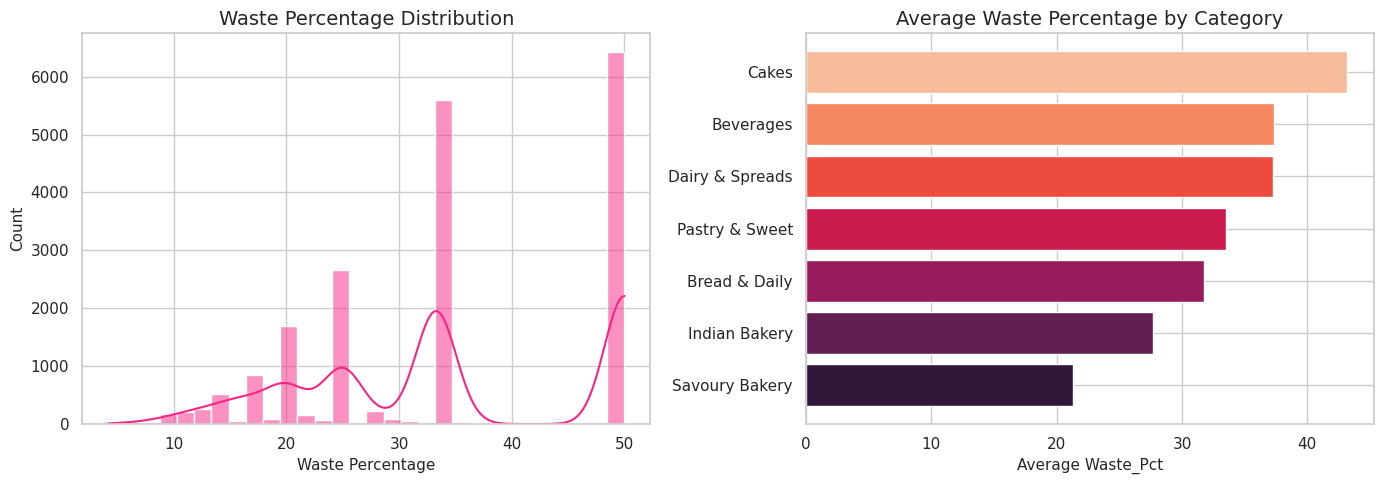

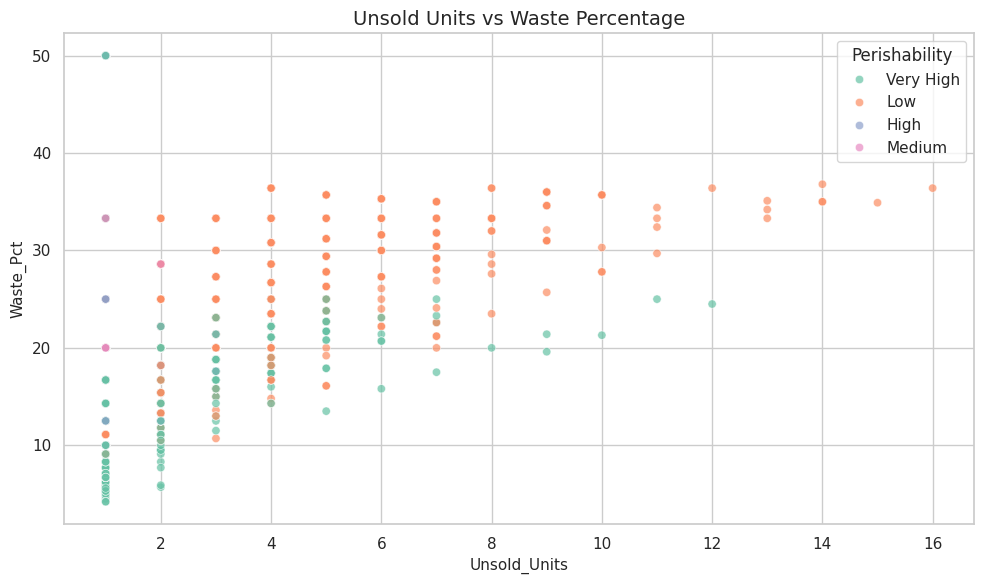

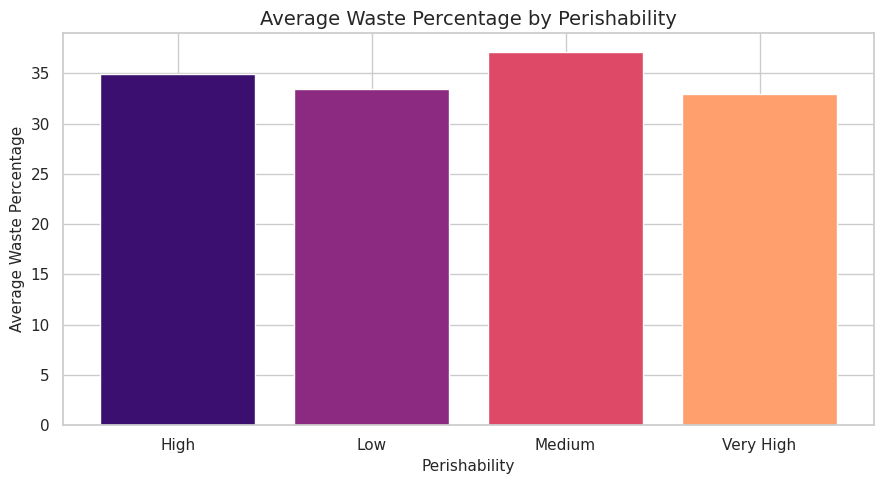

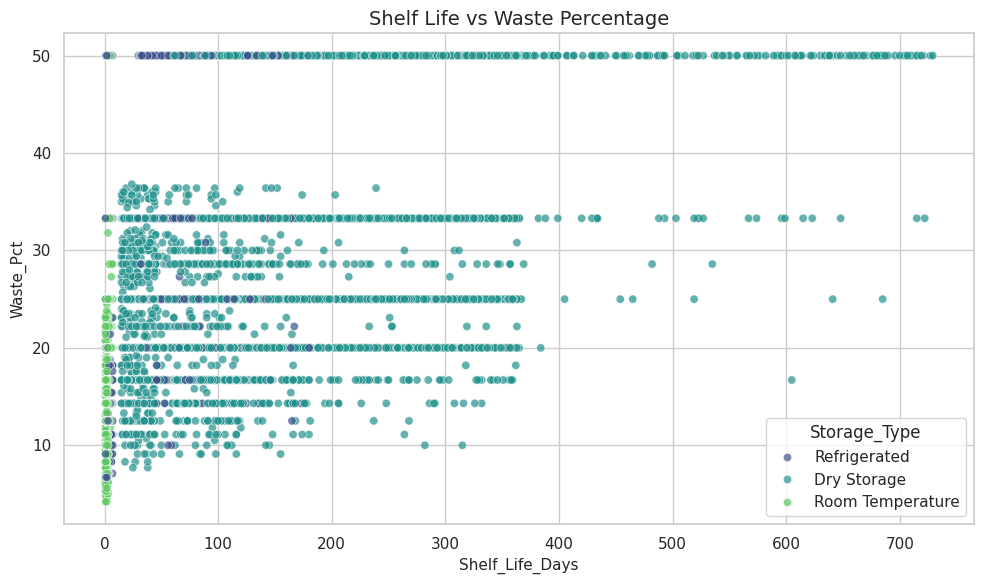

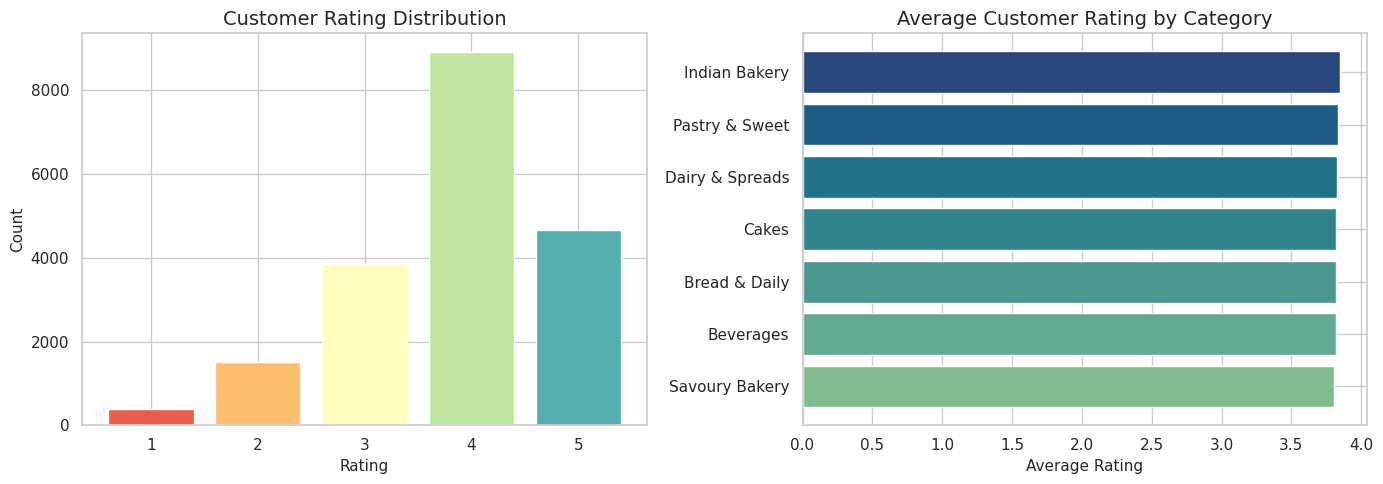

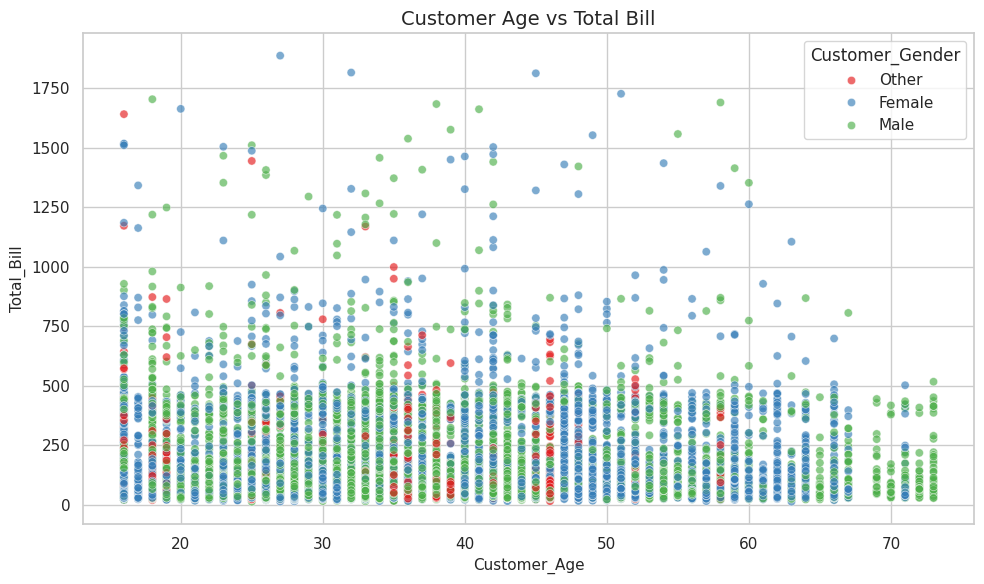

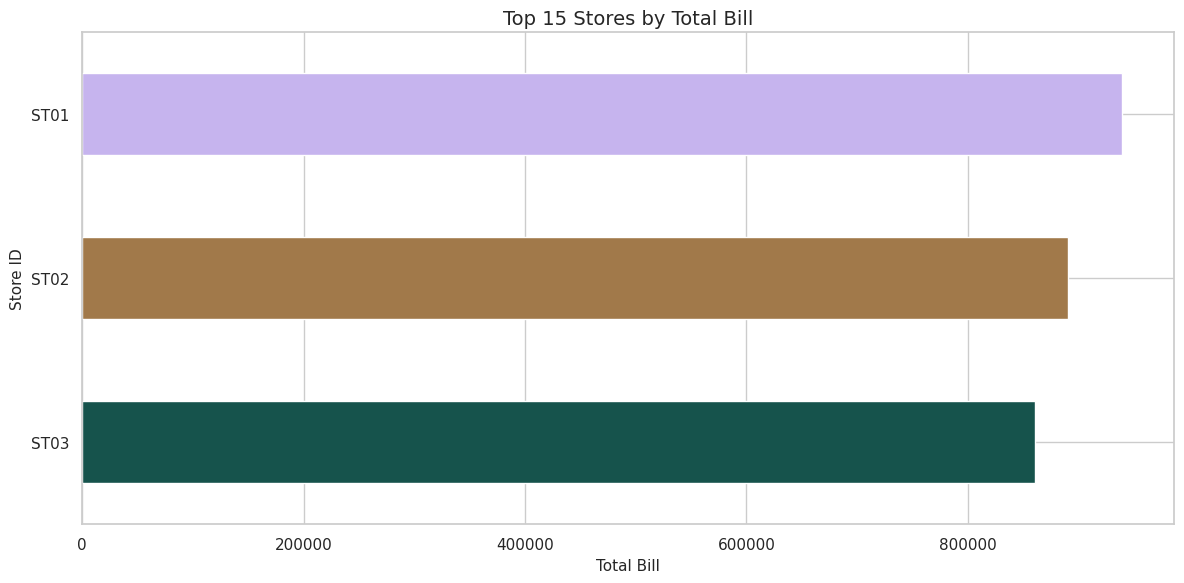

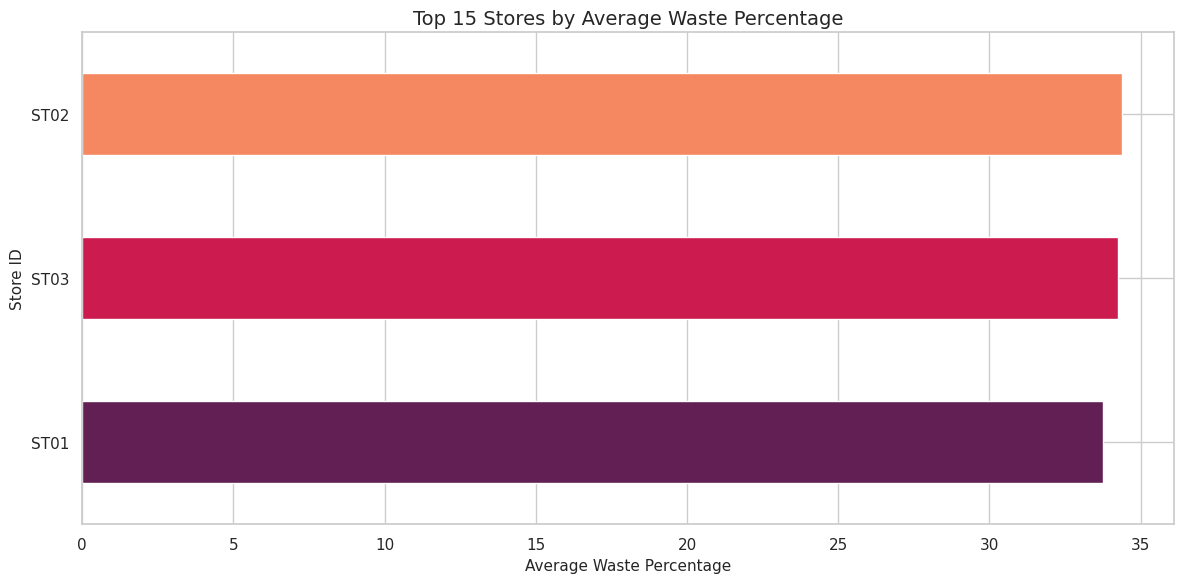

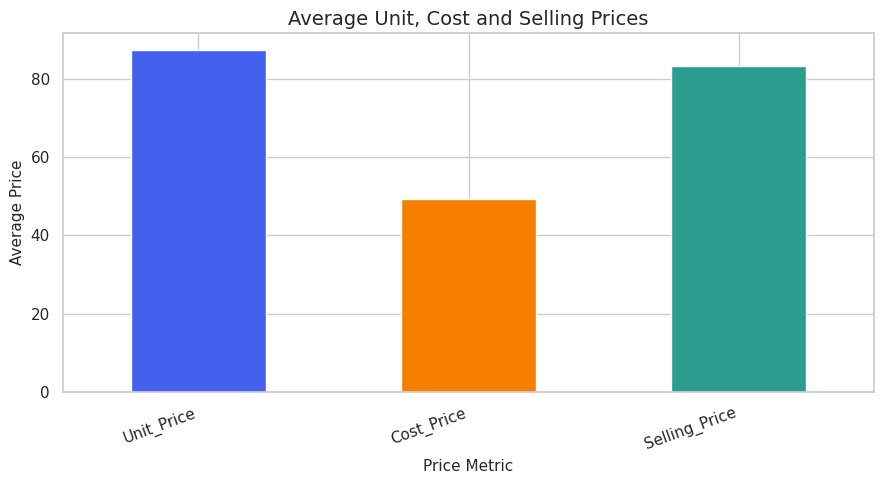

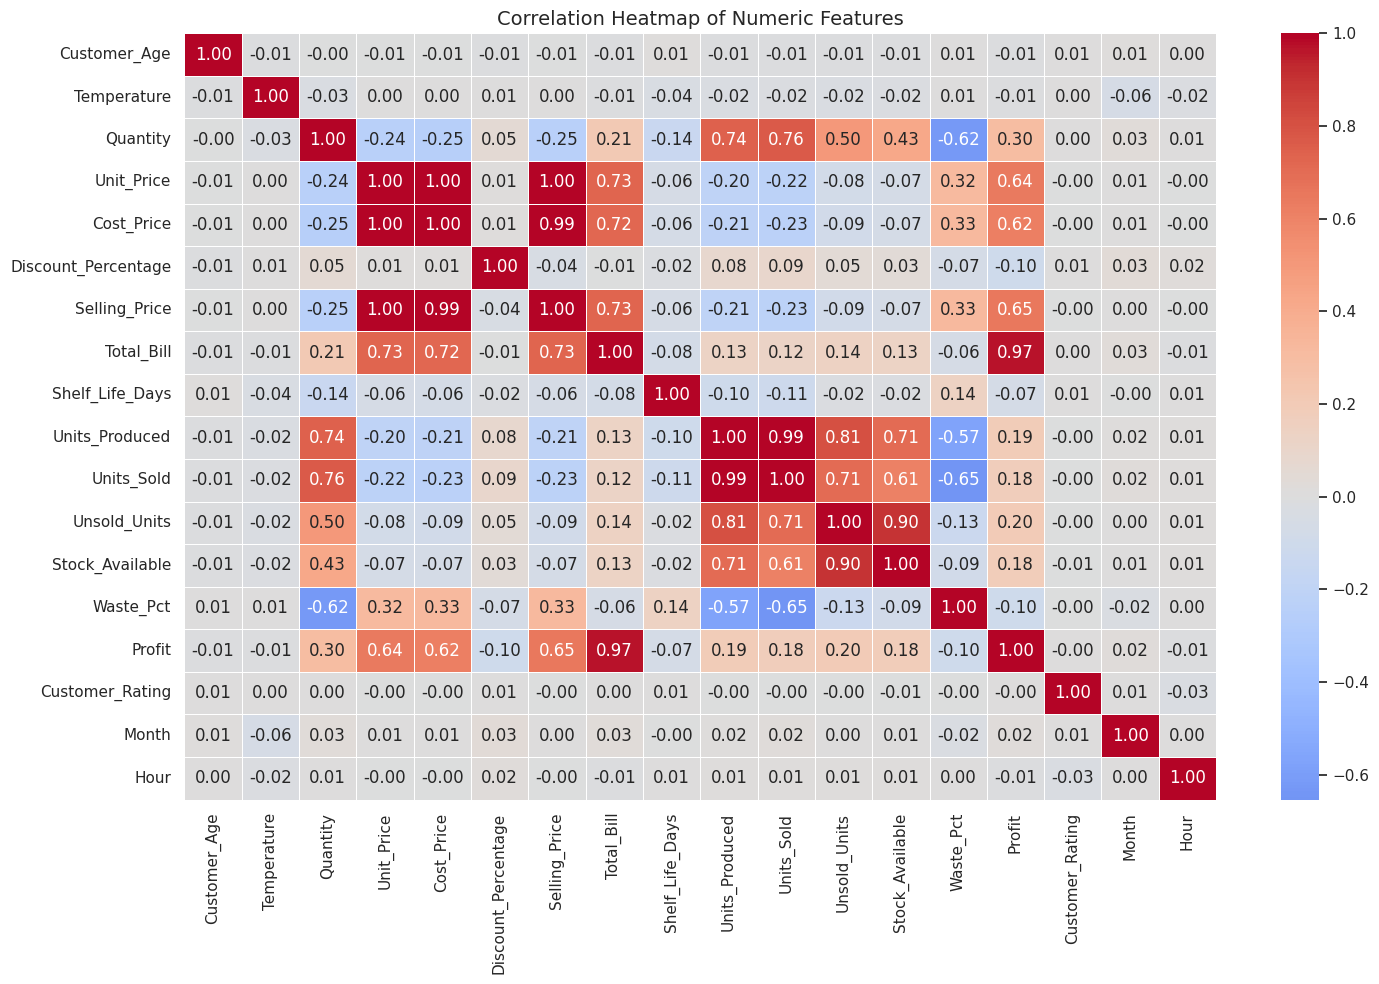

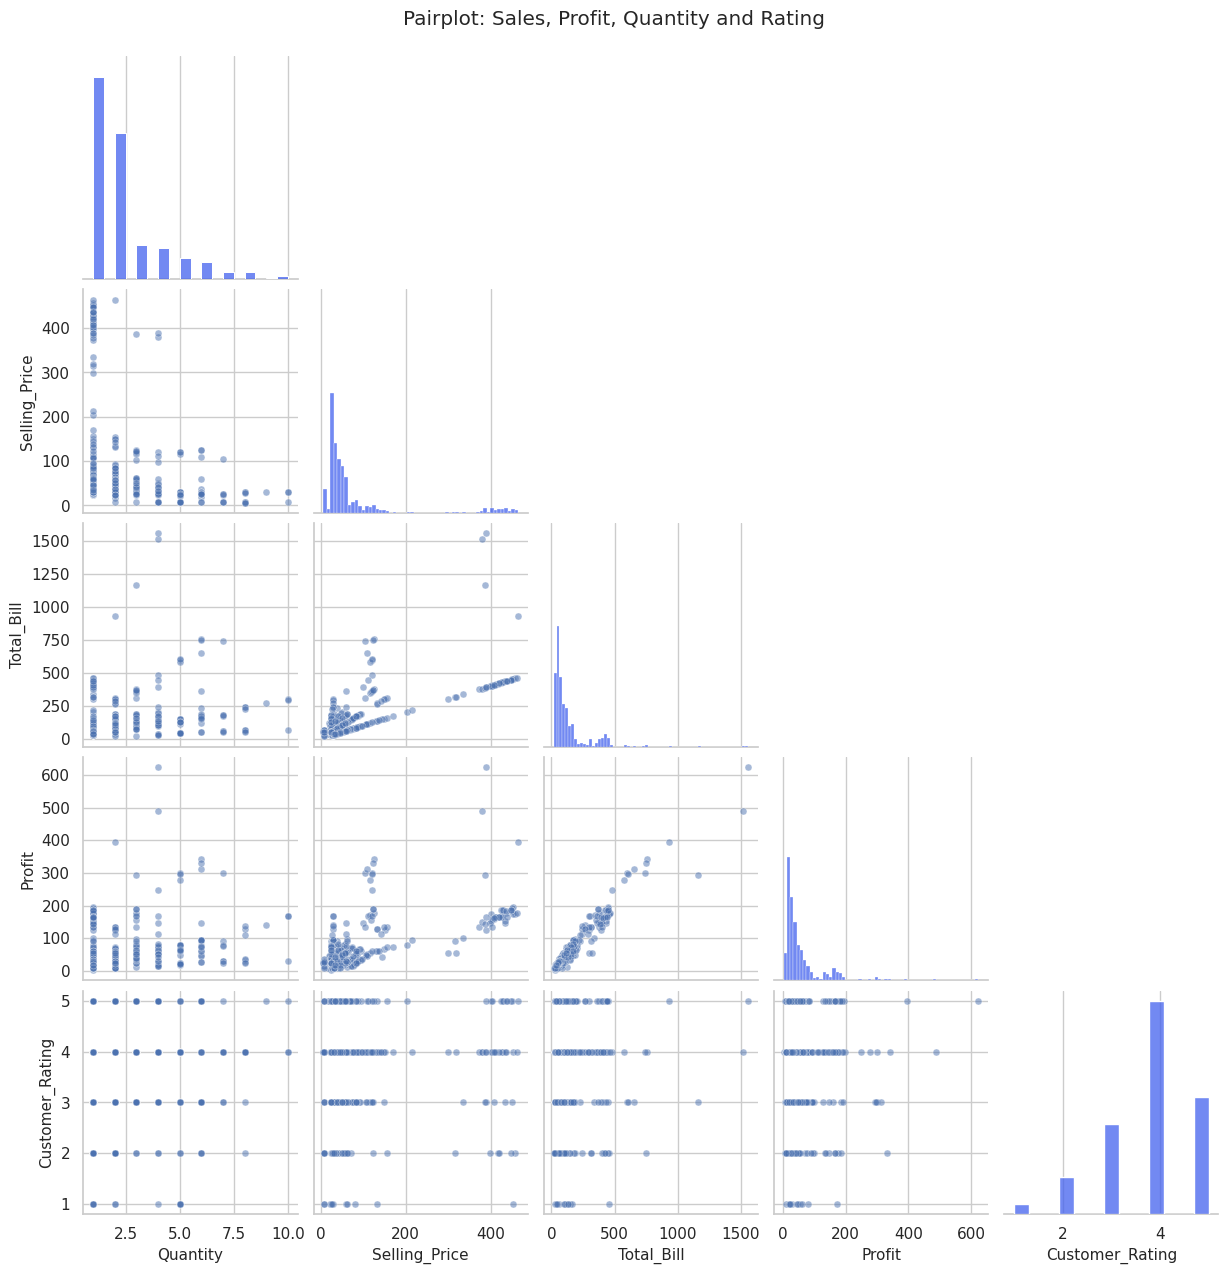


VISUALIZATION ANALYSIS COMPLETED
Total Rows: 19321
Total Columns: 40
Sum of Total_Bill: 2690806.05
Sum of Recorded Profit: 1143737.55
Total Units Sold: 58867
Total Unsold Units: 22696
Average Customer Rating: 3.83

All applicable charts have been generated successfully.


In [13]:

# ================================================================
# COMPLETE RETAIL SALES & INVENTORY DATA VISUALIZATION
# Multiple charts with different colors — single code
# DataFrame: df
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------
# 1. SET VISUALIZATION STYLE AND COLOR PALETTES
# ------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

colors = [
    "#4361EE", "#F72585", "#4CC9F0", "#7209B7",
    "#F77F00", "#2A9D8F", "#E63946", "#FFBE0B",
    "#8338EC", "#06D6A0", "#FB5607", "#3A86FF"
]

# ------------------------------------------------
# 2. CHECK DATASET
# ------------------------------------------------

if "df" not in globals():
    raise NameError("Please load your dataset into a DataFrame named df.")

if df.empty:
    raise ValueError("Your DataFrame is empty. Please load your dataset first.")

df = df.copy()

print("=" * 70)
print("RETAIL SALES, CUSTOMER & INVENTORY DATA ANALYSIS")
print("=" * 70)

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Values")
      .query("Missing_Values > 0")
)

print("\nDuplicate Rows:", df.duplicated().sum())

# ------------------------------------------------
# 3. PREPARE DATA WITHOUT MODIFYING ORIGINAL VALUES
# ------------------------------------------------

# Convert date column if it exists
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert known numeric columns
numeric_candidates = [
    "Customer_Age", "Year", "Month", "Day", "Hour",
    "Temperature", "Quantity", "Unit_Price", "Cost_Price",
    "Discount_Percentage", "Selling_Price", "Total_Bill",
    "Shelf_Life_Days", "Units_Produced", "Units_Sold",
    "Unsold_Units", "Stock_Available", "Waste_Pct",
    "Profit", "Customer_Rating"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

print("\nNumeric Columns:", numeric_cols)
print("\nCategorical Columns:", categorical_cols)

# Helper functions: skip charts if columns are missing or unusable
def has_cols(*cols):
    return all(col in df.columns for col in cols)

def numeric_data(col):
    if col not in df.columns:
        return pd.Series(dtype=float)
    return pd.to_numeric(df[col], errors="coerce").dropna()

def show_plot():
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 4. MISSING VALUE VISUALIZATION
# ------------------------------------------------

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(12, 6))
    missing.plot(
        kind="bar",
        color=sns.color_palette("rocket", n_colors=len(missing))
    )
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Value Count")
    plt.xticks(rotation=60, ha="right")
    show_plot()
else:
    print("\nNo missing values found.")

# ------------------------------------------------
# 5. NUMERIC FEATURE DISTRIBUTIONS
# ------------------------------------------------

distribution_cols = [
    "Customer_Age", "Quantity", "Unit_Price", "Cost_Price",
    "Discount_Percentage", "Selling_Price", "Total_Bill",
    "Temperature", "Profit", "Customer_Rating",
    "Units_Sold", "Unsold_Units", "Waste_Pct"
]

available_dist = [
    c for c in distribution_cols
    if c in df.columns and not numeric_data(c).empty
]

for i, col in enumerate(available_dist):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    sns.histplot(
        data=df, x=col, bins=30, kde=True,
        color=colors[i % len(colors)], ax=axes[0]
    )
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")

    sns.boxplot(
        data=df, x=col,
        color=colors[(i + 3) % len(colors)], ax=axes[1]
    )
    axes[1].set_title(f"Box Plot of {col}")
    axes[1].set_xlabel(col)

    show_plot()

# ------------------------------------------------
# 6. TOTAL BILL DISTRIBUTION
# ------------------------------------------------

if has_cols("Total_Bill"):
    values = numeric_data("Total_Bill")

    if not values.empty:
        plt.figure(figsize=(10, 5))
        sns.histplot(
            values, bins=35, kde=True,
            color="#4361EE", edgecolor="white"
        )
        plt.axvline(
            values.mean(), color="#F72585",
            linestyle="--", label=f"Mean: {values.mean():.2f}"
        )
        plt.axvline(
            values.median(), color="#2A9D8F",
            linestyle=":", label=f"Median: {values.median():.2f}"
        )
        plt.title("Total Bill Distribution")
        plt.xlabel("Total Bill")
        plt.ylabel("Number of Transactions")
        plt.legend()
        show_plot()

# ------------------------------------------------
# 7. SALES AND PROFIT SUMMARY
# ------------------------------------------------

summary_cols = [
    c for c in [
        "Quantity", "Selling_Price", "Total_Bill",
        "Profit", "Units_Sold", "Unsold_Units",
        "Stock_Available", "Waste_Pct", "Customer_Rating"
    ]
    if c in df.columns
]

if summary_cols:
    print("\nNumerical Summary:")
    display(df[summary_cols].describe().T.round(2))

# Sales and profit totals are calculated from existing fields.
# Do not add Total_Bill to Selling_Price: they may represent
# different levels of aggregation.
metric_cols = [
    c for c in ["Total_Bill", "Profit", "Units_Sold", "Unsold_Units"]
    if c in df.columns and not numeric_data(c).empty
]

if metric_cols:
    metric_totals = df[metric_cols].sum()

    plt.figure(figsize=(10, 5))
    metric_totals.plot(
        kind="bar",
        color=["#4361EE", "#F72585", "#2A9D8F", "#F77F00"][
            :len(metric_totals)
        ]
    )
    plt.title("Overall Sales, Profit and Inventory Metrics")
    plt.xlabel("Metric")
    plt.ylabel("Sum of Recorded Values")
    plt.xticks(rotation=25, ha="right")
    show_plot()

# ------------------------------------------------
# 8. SALES BY PRODUCT
# ------------------------------------------------

if has_cols("Product", "Total_Bill"):
    product_sales = (
        df.groupby("Product", dropna=False)["Total_Bill"]
        .sum()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 7))
    product_sales.sort_values().plot(
        kind="barh",
        color=sns.color_palette("viridis", len(product_sales))
    )
    plt.title("Top 15 Products by Total Bill")
    plt.xlabel("Sum of Total Bill")
    plt.ylabel("Product")
    show_plot()

# ------------------------------------------------
# 9. SALES BY CATEGORY
# ------------------------------------------------

if has_cols("Category", "Total_Bill"):
    category_sales = (
        df.groupby("Category", dropna=False)["Total_Bill"]
        .sum()
        .sort_values(ascending=False)
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    category_sales.plot(
        kind="bar",
        ax=axes[0],
        color=sns.color_palette("Set2", len(category_sales))
    )
    axes[0].set_title("Total Bill by Category")
    axes[0].set_xlabel("Category")
    axes[0].set_ylabel("Total Bill")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].pie(
        category_sales.values,
        labels=category_sales.index.astype(str),
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("Set3", len(category_sales))
    )
    axes[1].set_title("Category Share of Total Bill")
    show_plot()

# ------------------------------------------------
# 10. PROFIT BY PRODUCT AND CATEGORY
# ------------------------------------------------

if has_cols("Product", "Profit"):
    product_profit = (
        df.groupby("Product")["Profit"]
        .sum()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 7))
    product_profit.sort_values().plot(
        kind="barh",
        color=sns.color_palette("coolwarm", len(product_profit))
    )
    plt.title("Top 15 Products by Recorded Profit")
    plt.xlabel("Sum of Profit")
    plt.ylabel("Product")
    plt.axvline(0, color="black", linewidth=0.8)
    show_plot()

if has_cols("Category", "Profit"):
    category_profit = df.groupby("Category")["Profit"].sum().sort_values()

    plt.figure(figsize=(11, 6))
    category_profit.plot(
        kind="bar",
        color=[
            "#E63946" if x < 0 else "#2A9D8F"
            for x in category_profit.values
        ]
    )
    plt.title("Profit by Category")
    plt.xlabel("Category")
    plt.ylabel("Sum of Profit")
    plt.xticks(rotation=45, ha="right")
    plt.axhline(0, color="black", linewidth=0.8)
    show_plot()

# ------------------------------------------------
# 11. CUSTOMER GENDER ANALYSIS
# ------------------------------------------------

if "Customer_Gender" in df.columns:
    gender_counts = df["Customer_Gender"].fillna("Unknown").value_counts()

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=gender_counts.index.astype(str),
        y=gender_counts.values,
        hue=gender_counts.index.astype(str),
        palette="pastel",
        legend=False
    )
    plt.title("Customer Count by Gender")
    plt.xlabel("Customer Gender")
    plt.ylabel("Transaction Rows")
    show_plot()

# ------------------------------------------------
# 12. CUSTOMER SEGMENT ANALYSIS
# ------------------------------------------------

if "Customer_Segment" in df.columns:
    segment_counts = (
        df["Customer_Segment"].fillna("Unknown").value_counts()
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=segment_counts.index.astype(str),
        y=segment_counts.values,
        hue=segment_counts.index.astype(str),
        palette="husl",
        legend=False
    )
    plt.title("Customer Segment Distribution")
    plt.xlabel("Customer Segment")
    plt.ylabel("Transaction Rows")
    plt.xticks(rotation=35, ha="right")
    show_plot()

# ------------------------------------------------
# 13. LOYALTY MEMBER ANALYSIS
# ------------------------------------------------

if "Loyalty_Member" in df.columns:
    loyalty_counts = (
        df["Loyalty_Member"].fillna("Unknown").value_counts()
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(
        loyalty_counts.index.astype(str),
        loyalty_counts.values,
        color=["#06D6A0", "#F77F00", "#4361EE"][
            :len(loyalty_counts)
        ]
    )
    axes[0].set_title("Loyalty Member Distribution")
    axes[0].set_xlabel("Loyalty Member")
    axes[0].set_ylabel("Transaction Rows")

    if has_cols("Loyalty_Member", "Total_Bill"):
        loyalty_sales = df.groupby("Loyalty_Member")["Total_Bill"].sum()
        axes[1].bar(
            loyalty_sales.index.astype(str),
            loyalty_sales.values,
            color=sns.color_palette("Set2", len(loyalty_sales))
        )
        axes[1].set_title("Total Bill by Loyalty Status")
        axes[1].set_xlabel("Loyalty Member")
        axes[1].set_ylabel("Total Bill")
    else:
        axes[1].text(0.5, 0.5, "Total_Bill column unavailable",
                     ha="center", va="center")
        axes[1].set_axis_off()

    show_plot()

# ------------------------------------------------
# 14. PAYMENT METHOD ANALYSIS
# ------------------------------------------------

if "Payment_Method" in df.columns:
    payment_counts = (
        df["Payment_Method"].fillna("Unknown").value_counts()
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].bar(
        payment_counts.index.astype(str),
        payment_counts.values,
        color=sns.color_palette("bright", len(payment_counts))
    )
    axes[0].set_title("Transactions by Payment Method")
    axes[0].set_xlabel("Payment Method")
    axes[0].set_ylabel("Transaction Rows")
    axes[0].tick_params(axis="x", rotation=35)

    if has_cols("Payment_Method", "Total_Bill"):
        payment_sales = df.groupby("Payment_Method")["Total_Bill"].sum()
        axes[1].bar(
            payment_sales.index.astype(str),
            payment_sales.values,
            color=sns.color_palette("magma", len(payment_sales))
        )
        axes[1].set_title("Total Bill by Payment Method")
        axes[1].set_xlabel("Payment Method")
        axes[1].set_ylabel("Total Bill")
        axes[1].tick_params(axis="x", rotation=35)

    show_plot()

# ------------------------------------------------
# 15. PROMOTION ANALYSIS
# ------------------------------------------------

if "Promotion_Applied" in df.columns:
    promo_counts = (
        df["Promotion_Applied"].fillna("Unknown").value_counts()
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        promo_counts.index.astype(str),
        promo_counts.values,
        color=["#F72585", "#4361EE", "#4CC9F0"][
            :len(promo_counts)
        ]
    )
    plt.title("Transactions by Promotion Status")
    plt.xlabel("Promotion Applied")
    plt.ylabel("Transaction Rows")
    show_plot()

    if has_cols("Promotion_Applied", "Total_Bill"):
        promo_sales = df.groupby("Promotion_Applied")["Total_Bill"].sum()

        plt.figure(figsize=(9, 5))
        promo_sales.plot(
            kind="bar",
            color=sns.color_palette("Set1", len(promo_sales))
        )
        plt.title("Total Bill by Promotion Status")
        plt.xlabel("Promotion Applied")
        plt.ylabel("Total Bill")
        plt.xticks(rotation=0)
        show_plot()

if has_cols("Promotion_Type", "Profit"):
    promotion_profit = (
        df.groupby("Promotion_Type")["Profit"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(11, 5))
    promotion_profit.plot(
        kind="bar",
        color=sns.color_palette("Spectral", len(promotion_profit))
    )
    plt.title("Profit by Promotion Type")
    plt.xlabel("Promotion Type")
    plt.ylabel("Sum of Profit")
    plt.xticks(rotation=35, ha="right")
    show_plot()

# ------------------------------------------------
# 16. MONTHLY SALES TREND
# ------------------------------------------------

if has_cols("Month", "Total_Bill"):
    monthly_sales = (
        df.groupby("Month")["Total_Bill"].sum().sort_index()
    )

    plt.figure(figsize=(12, 5))
    plt.plot(
        monthly_sales.index, monthly_sales.values,
        marker="o", linewidth=2.5, color="#4361EE"
    )
    plt.fill_between(
        monthly_sales.index, monthly_sales.values,
        alpha=0.15, color="#4CC9F0"
    )
    plt.title("Monthly Total Bill Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Bill")
    plt.xticks(range(1, 13))
    plt.grid(True, alpha=0.3)
    show_plot()

# ------------------------------------------------
# 17. YEARLY SALES TREND
# ------------------------------------------------

if has_cols("Year", "Total_Bill"):
    yearly_sales = df.groupby("Year")["Total_Bill"].sum().sort_index()

    plt.figure(figsize=(10, 5))
    plt.bar(
        yearly_sales.index.astype(str),
        yearly_sales.values,
        color=sns.color_palette("viridis", len(yearly_sales))
    )
    plt.title("Yearly Total Bill")
    plt.xlabel("Year")
    plt.ylabel("Total Bill")
    show_plot()

# ------------------------------------------------
# 18. DAY OF WEEK ANALYSIS
# ------------------------------------------------

if has_cols("Day_of_Week", "Total_Bill"):
    day_sales = df.groupby("Day_of_Week")["Total_Bill"].sum()

    # Use calendar ordering when day names are present
    day_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]

    if set(day_sales.index.astype(str)).issubset(set(day_order)):
        day_sales.index = day_sales.index.astype(str)
        day_sales = day_sales.reindex(day_order).dropna()
    else:
        day_sales = day_sales.sort_values(ascending=False)

    plt.figure(figsize=(11, 5))
    plt.bar(
        day_sales.index.astype(str), day_sales.values,
        color=sns.color_palette("husl", len(day_sales))
    )
    plt.title("Total Bill by Day of Week")
    plt.xlabel("Day of Week")
    plt.ylabel("Total Bill")
    plt.xticks(rotation=30, ha="right")
    show_plot()

# ------------------------------------------------
# 19. WEEKEND VS WEEKDAY
# ------------------------------------------------

if has_cols("Weekend", "Total_Bill"):
    weekend_sales = df.groupby("Weekend")["Total_Bill"].sum()

    plt.figure(figsize=(8, 5))
    plt.bar(
        weekend_sales.index.astype(str),
        weekend_sales.values,
        color=["#2A9D8F", "#F72585"][:len(weekend_sales)]
    )
    plt.title("Total Bill: Weekend vs Weekday")
    plt.xlabel("Weekend")
    plt.ylabel("Total Bill")
    show_plot()

# ------------------------------------------------
# 20. HOURLY SALES TREND
# ------------------------------------------------

if has_cols("Hour", "Total_Bill"):
    hourly_sales = df.groupby("Hour")["Total_Bill"].sum().sort_index()

    plt.figure(figsize=(12, 5))
    plt.plot(
        hourly_sales.index, hourly_sales.values,
        color="#F77F00", marker="o", linewidth=2
    )
    plt.title("Hourly Total Bill Trend")
    plt.xlabel("Hour of Day")
    plt.ylabel("Total Bill")
    plt.xticks(range(0, 24))
    plt.grid(True, alpha=0.3)
    show_plot()

# ------------------------------------------------
# 21. SEASONAL ANALYSIS
# ------------------------------------------------

if has_cols("Season", "Total_Bill"):
    seasonal_sales = df.groupby("Season")["Total_Bill"].sum()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(
        seasonal_sales.index.astype(str),
        seasonal_sales.values,
        color=sns.color_palette("coolwarm", len(seasonal_sales))
    )
    axes[0].set_title("Total Bill by Season")
    axes[0].set_xlabel("Season")
    axes[0].set_ylabel("Total Bill")

    if has_cols("Season", "Profit"):
        seasonal_profit = df.groupby("Season")["Profit"].sum()
        axes[1].bar(
            seasonal_profit.index.astype(str),
            seasonal_profit.values,
            color=sns.color_palette("viridis", len(seasonal_profit))
        )
        axes[1].set_title("Profit by Season")
        axes[1].set_xlabel("Season")
        axes[1].set_ylabel("Profit")

    show_plot()

# ------------------------------------------------
# 22. FESTIVAL ANALYSIS
# ------------------------------------------------

if has_cols("Festival", "Total_Bill"):
    festival_sales = (
        df.groupby("Festival")["Total_Bill"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(11, 5))
    festival_sales.plot(
        kind="bar",
        color=sns.color_palette("flare", len(festival_sales))
    )
    plt.title("Total Bill by Festival")
    plt.xlabel("Festival")
    plt.ylabel("Total Bill")
    plt.xticks(rotation=35, ha="right")
    show_plot()

# ------------------------------------------------
# 23. WEATHER AND TEMPERATURE ANALYSIS
# ------------------------------------------------

if has_cols("Weather", "Total_Bill"):
    weather_sales = df.groupby("Weather")["Total_Bill"].sum()

    plt.figure(figsize=(10, 5))
    weather_sales.plot(
        kind="bar",
        color=sns.color_palette("YlGnBu", len(weather_sales))
    )
    plt.title("Total Bill by Weather Condition")
    plt.xlabel("Weather")
    plt.ylabel("Total Bill")
    plt.xticks(rotation=30, ha="right")
    show_plot()

if has_cols("Temperature", "Total_Bill"):
    temp_df = df[["Temperature", "Total_Bill"]].dropna()

    if len(temp_df) > 1:
        plt.figure(figsize=(10, 6))
        sns.regplot(
            data=temp_df,
            x="Temperature",
            y="Total_Bill",
            scatter_kws={"alpha": 0.4, "color": "#4361EE"},
            line_kws={"color": "#F72585"}
        )
        plt.title("Temperature vs Total Bill")
        show_plot()

# ------------------------------------------------
# 24. DISCOUNT ANALYSIS
# ------------------------------------------------

if has_cols("Discount_Percentage", "Total_Bill"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Discount_Percentage",
        y="Total_Bill",
        hue="Category" if "Category" in df.columns else None,
        palette="husl",
        alpha=0.7
    )
    plt.title("Discount Percentage vs Total Bill")
    show_plot()

if has_cols("Discount_Percentage", "Profit"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Discount_Percentage",
        y="Profit",
        hue="Promotion_Applied" if "Promotion_Applied" in df.columns else None,
        palette="Set1",
        alpha=0.7
    )
    plt.title("Discount Percentage vs Profit")
    plt.axhline(0, color="black", linewidth=0.8)
    show_plot()

# ------------------------------------------------
# 25. QUANTITY VS TOTAL BILL
# ------------------------------------------------

if has_cols("Quantity", "Total_Bill"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Quantity",
        y="Total_Bill",
        hue="Customer_Segment" if "Customer_Segment" in df.columns else None,
        palette="husl",
        alpha=0.65
    )
    plt.title("Quantity vs Total Bill")
    show_plot()

# ------------------------------------------------
# 26. INVENTORY ANALYSIS
# ------------------------------------------------

inventory_cols = [
    c for c in ["Units_Produced", "Units_Sold", "Unsold_Units",
                "Stock_Available"]
    if c in df.columns
]

if inventory_cols:
    inventory_totals = df[inventory_cols].sum()

    plt.figure(figsize=(11, 5))
    inventory_totals.plot(
        kind="bar",
        color=["#4361EE", "#2A9D8F", "#F72585", "#F77F00"][
            :len(inventory_totals)
        ]
    )
    plt.title("Overall Production, Sales and Inventory")
    plt.xlabel("Inventory Metric")
    plt.ylabel("Sum of Recorded Units")
    plt.xticks(rotation=25, ha="right")
    show_plot()

# ------------------------------------------------
# 27. INVENTORY METRICS BY CATEGORY
# ------------------------------------------------

if has_cols("Category", "Units_Sold", "Unsold_Units"):
    inventory_category = df.groupby("Category")[
        ["Units_Sold", "Unsold_Units"]
    ].sum()

    inventory_category.plot(
        kind="bar",
        figsize=(12, 6),
        color=["#2A9D8F", "#E63946"]
    )
    plt.title("Units Sold vs Unsold Units by Category")
    plt.xlabel("Category")
    plt.ylabel("Units")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Inventory Metric")
    show_plot()

# ------------------------------------------------
# 28. WASTE PERCENTAGE ANALYSIS
# ------------------------------------------------

if "Waste_Pct" in df.columns:
    waste = numeric_data("Waste_Pct")

    if not waste.empty:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        sns.histplot(
            waste, bins=30, kde=True,
            color="#F72585", ax=axes[0]
        )
        axes[0].set_title("Waste Percentage Distribution")
        axes[0].set_xlabel("Waste Percentage")

        if "Category" in df.columns:
            waste_cat = (
                df.groupby("Category")["Waste_Pct"].mean().sort_values()
            )
            axes[1].barh(
                waste_cat.index.astype(str), waste_cat.values,
                color=sns.color_palette("rocket", len(waste_cat))
            )
            axes[1].set_title("Average Waste Percentage by Category")
            axes[1].set_xlabel("Average Waste_Pct")
        else:
            axes[1].text(0.5, 0.5, "Category column unavailable",
                         ha="center", va="center")
            axes[1].set_axis_off()

        show_plot()

# ------------------------------------------------
# 29. UNSOLD UNITS VS WASTE
# ------------------------------------------------

if has_cols("Unsold_Units", "Waste_Pct"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Unsold_Units",
        y="Waste_Pct",
        hue="Perishability" if "Perishability" in df.columns else None,
        palette="Set2",
        alpha=0.7
    )
    plt.title("Unsold Units vs Waste Percentage")
    show_plot()

# ------------------------------------------------
# 30. SHELF LIFE AND PERISHABILITY
# ------------------------------------------------

if has_cols("Perishability", "Waste_Pct"):
    perishability_waste = df.groupby("Perishability")["Waste_Pct"].mean()

    plt.figure(figsize=(9, 5))
    plt.bar(
        perishability_waste.index.astype(str),
        perishability_waste.values,
        color=sns.color_palette("magma", len(perishability_waste))
    )
    plt.title("Average Waste Percentage by Perishability")
    plt.xlabel("Perishability")
    plt.ylabel("Average Waste Percentage")
    show_plot()

if has_cols("Shelf_Life_Days", "Waste_Pct"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Shelf_Life_Days",
        y="Waste_Pct",
        hue="Storage_Type" if "Storage_Type" in df.columns else None,
        palette="viridis",
        alpha=0.7
    )
    plt.title("Shelf Life vs Waste Percentage")
    show_plot()

# ------------------------------------------------
# 31. CUSTOMER RATING ANALYSIS
# ------------------------------------------------

if "Customer_Rating" in df.columns:
    rating = numeric_data("Customer_Rating")

    if not rating.empty:
        rating_counts = rating.value_counts().sort_index()

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].bar(
            rating_counts.index.astype(str),
            rating_counts.values,
            color=sns.color_palette("Spectral", len(rating_counts))
        )
        axes[0].set_title("Customer Rating Distribution")
        axes[0].set_xlabel("Rating")
        axes[0].set_ylabel("Count")

        if has_cols("Category", "Customer_Rating"):
            rating_category = df.groupby("Category")[
                "Customer_Rating"
            ].mean().sort_values()

            axes[1].barh(
                rating_category.index.astype(str),
                rating_category.values,
                color=sns.color_palette("crest", len(rating_category))
            )
            axes[1].set_title("Average Customer Rating by Category")
            axes[1].set_xlabel("Average Rating")

        show_plot()

# ------------------------------------------------
# 32. CUSTOMER AGE VS TOTAL BILL
# ------------------------------------------------

if has_cols("Customer_Age", "Total_Bill"):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Customer_Age",
        y="Total_Bill",
        hue="Customer_Gender" if "Customer_Gender" in df.columns else None,
        palette="Set1",
        alpha=0.65
    )
    plt.title("Customer Age vs Total Bill")
    show_plot()

# ------------------------------------------------
# 33. STORE PERFORMANCE
# ------------------------------------------------

if has_cols("Store_ID", "Total_Bill"):
    store_sales = (
        df.groupby("Store_ID")["Total_Bill"]
        .sum()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 6))
    store_sales.sort_values().plot(
        kind="barh",
        color=sns.color_palette("cubehelix", len(store_sales))
    )
    plt.title("Top 15 Stores by Total Bill")
    plt.xlabel("Total Bill")
    plt.ylabel("Store ID")
    show_plot()

if has_cols("Store_ID", "Waste_Pct"):
    store_waste = (
        df.groupby("Store_ID")["Waste_Pct"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 6))
    store_waste.sort_values().plot(
        kind="barh",
        color=sns.color_palette("rocket", len(store_waste))
    )
    plt.title("Top 15 Stores by Average Waste Percentage")
    plt.xlabel("Average Waste Percentage")
    plt.ylabel("Store ID")
    show_plot()

# ------------------------------------------------
# 34. PRICE COMPARISON
# ------------------------------------------------

price_cols = [
    c for c in ["Unit_Price", "Cost_Price", "Selling_Price"]
    if c in df.columns
]

if price_cols:
    price_means = df[price_cols].mean()

    plt.figure(figsize=(9, 5))
    price_means.plot(
        kind="bar",
        color=["#4361EE", "#F77F00", "#2A9D8F"][:len(price_means)]
    )
    plt.title("Average Unit, Cost and Selling Prices")
    plt.xlabel("Price Metric")
    plt.ylabel("Average Price")
    plt.xticks(rotation=20, ha="right")
    show_plot()

# ------------------------------------------------
# 35. CORRELATION HEATMAP
# ------------------------------------------------

correlation_cols = [
    c for c in [
        "Customer_Age", "Temperature", "Quantity",
        "Unit_Price", "Cost_Price", "Discount_Percentage",
        "Selling_Price", "Total_Bill", "Shelf_Life_Days",
        "Units_Produced", "Units_Sold", "Unsold_Units",
        "Stock_Available", "Waste_Pct", "Profit",
        "Customer_Rating", "Month", "Hour"
    ]
    if c in df.columns and df[c].nunique(dropna=True) > 1
]

if len(correlation_cols) >= 2:
    corr = df[correlation_cols].corr()

    plt.figure(figsize=(15, 10))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5,
        square=False
    )
    plt.title("Correlation Heatmap of Numeric Features")
    show_plot()

# ------------------------------------------------
# 36. PAIRPLOT FOR SELECTED NUMERIC FEATURES
# ------------------------------------------------

pair_cols = [
    c for c in [
        "Quantity", "Selling_Price", "Total_Bill",
        "Profit", "Customer_Rating"
    ]
    if c in df.columns and df[c].nunique(dropna=True) > 1
]

if len(pair_cols) >= 2:
    pair_df = df[pair_cols].dropna()

    # Sample large datasets to keep the pairplot efficient
    if len(pair_df) > 500:
        pair_df = pair_df.sample(500, random_state=42)

    if len(pair_df) >= 2:
        g = sns.pairplot(
            pair_df,
            diag_kind="hist",
            corner=True,
            plot_kws={"alpha": 0.5, "s": 25},
            diag_kws={"color": "#4361EE"}
        )
        g.fig.suptitle(
            "Pairplot: Sales, Profit, Quantity and Rating",
            y=1.02
        )
        plt.show()

# ------------------------------------------------
# 37. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("VISUALIZATION ANALYSIS COMPLETED")
print("=" * 70)

print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))

if "Total_Bill" in df.columns:
    print("Sum of Total_Bill:", round(df["Total_Bill"].sum(), 2))

if "Profit" in df.columns:
    print("Sum of Recorded Profit:", round(df["Profit"].sum(), 2))

if "Units_Sold" in df.columns:
    print("Total Units Sold:", round(df["Units_Sold"].sum(), 2))

if "Unsold_Units" in df.columns:
    print("Total Unsold Units:", round(df["Unsold_Units"].sum(), 2))

if "Customer_Rating" in df.columns:
    print("Average Customer Rating:",
          round(df["Customer_Rating"].mean(), 2))

print("\nAll applicable charts have been generated successfully.")


## Feature engineering

RETAIL CUSTOMER RATING - MACHINE LEARNING

Original Dataset Shape: (19321, 40)

Target Column: Customer_Rating
Rows with valid ratings: 19321
Observed rating classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Target Class Distribution:
Customer_Rating
1     378
2    1513
3    3841
4    8917
5    4672
Name: count, dtype: int64

Feature Matrix Shape: (19321, 34)
Number of Features: 34
Number of Classes: 5
Rating Label Mapping:
  1 -> 0
  2 -> 1
  3 -> 2
  4 -> 3
  5 -> 4

Training Rows: 15456
Testing Rows: 3865

Training Class Distribution:
1     302
2    1210
3    3073
4    7133
5    3738
Name: count, dtype: int64

Testing Class Distribution:
1      76
2     303
3     768
4    1784
5     934
Name: count, dtype: int64

Categorical Features Label Encoded: ['Customer_Gender', 'Customer_Segment', 'Loyalty_Member', 'Day_of_Week', 'Weekend', 'Season', 'Festival', 'Weather', 'Product', 'Category', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type', 'Storage_Type',

,Model,Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,ROC_AUC
0,Extra Trees,0.8103,0.8281,0.8103,0.8063,0.9385
1,Random Forest,0.5599,0.6612,0.5599,0.4896,0.7857
2,K-Nearest Neighbors,0.4554,0.4351,0.4554,0.4334,0.6289
3,Decision Tree,0.3633,0.4708,0.3633,0.3782,0.6631
4,Support Vector Machine,0.2939,0.3886,0.2939,0.3143,0.5935
5,Gradient Boosting,0.4652,0.5239,0.4652,0.3060,0.6140
6,Logistic Regression,0.1718,0.3294,0.1718,0.2063,0.5288


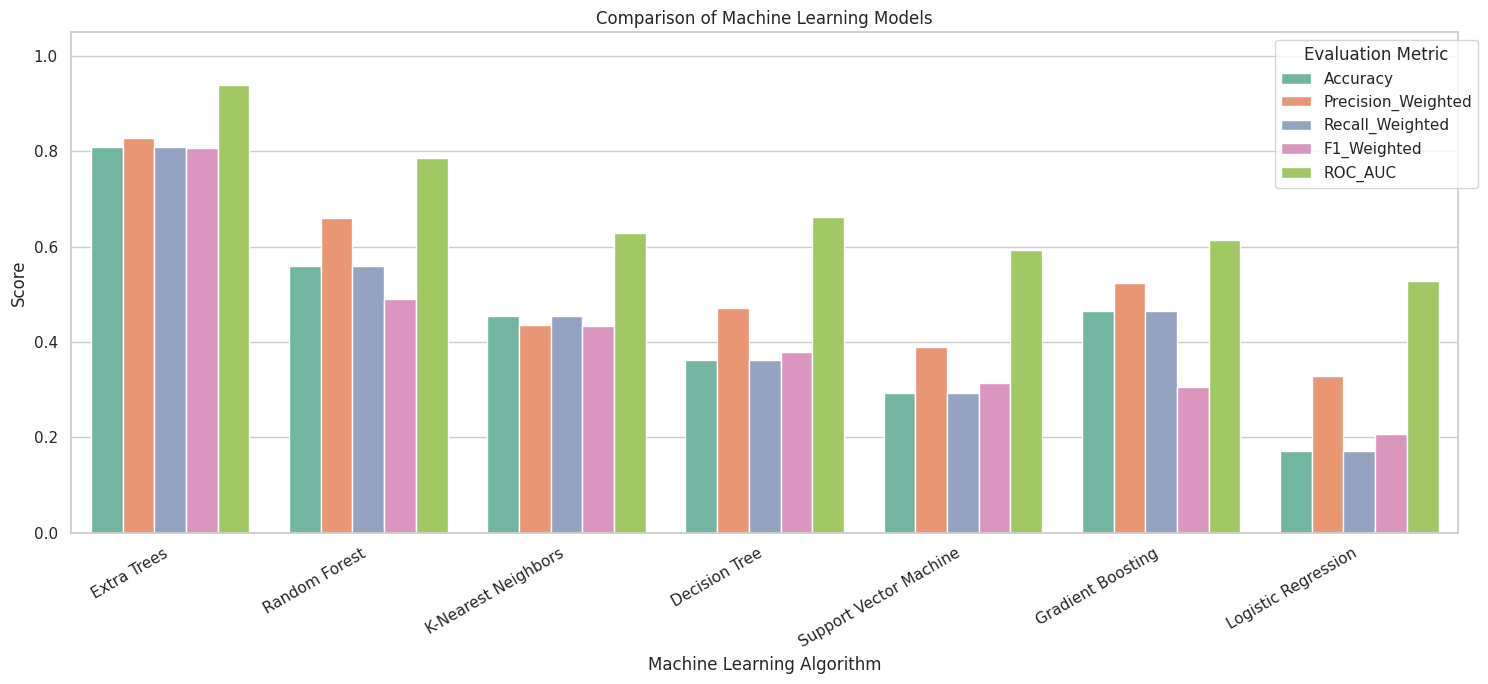

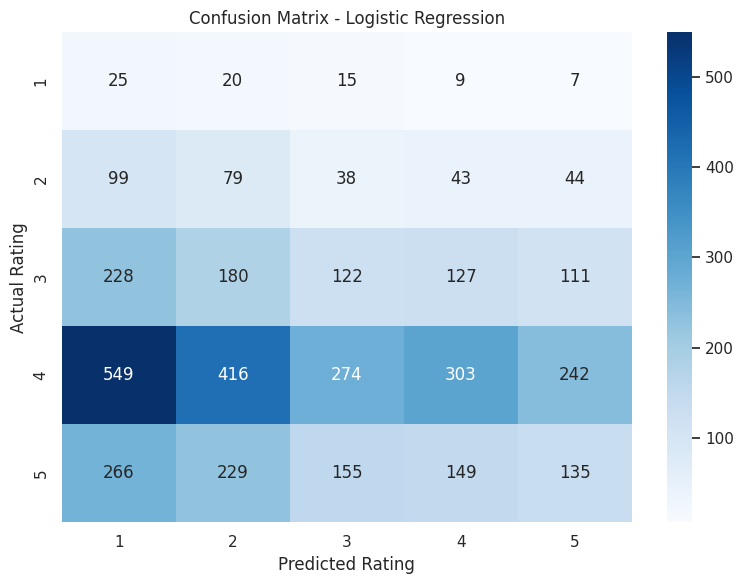

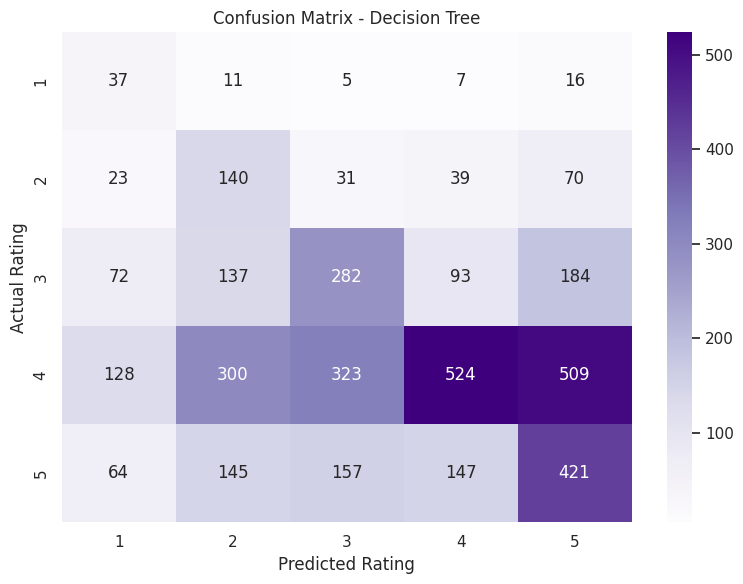

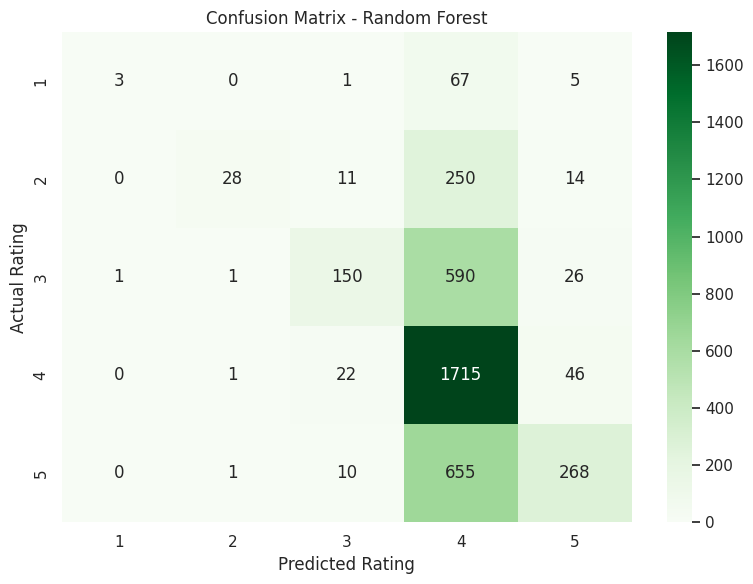

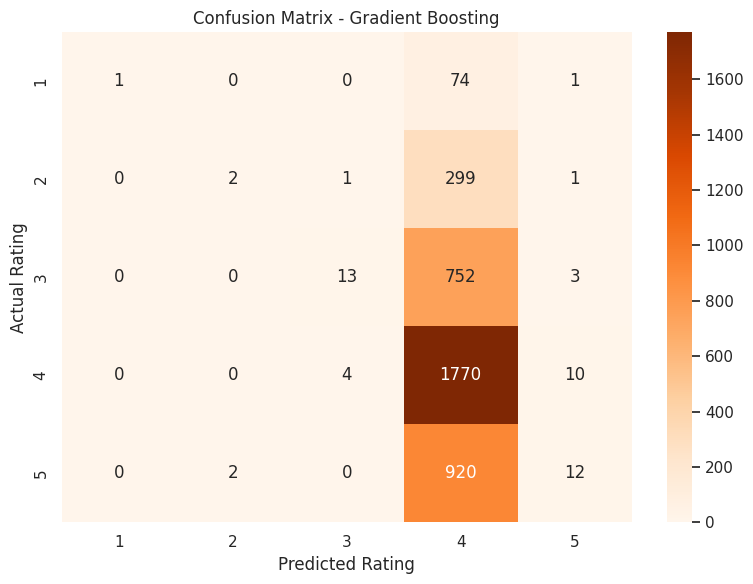

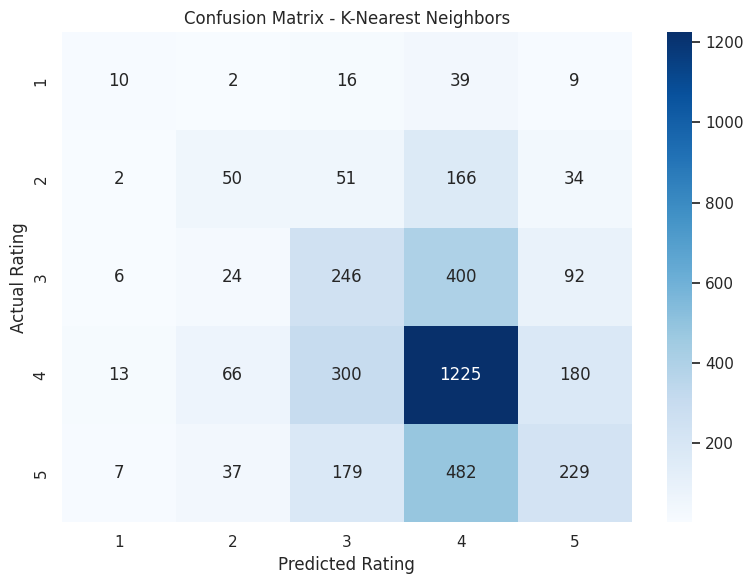

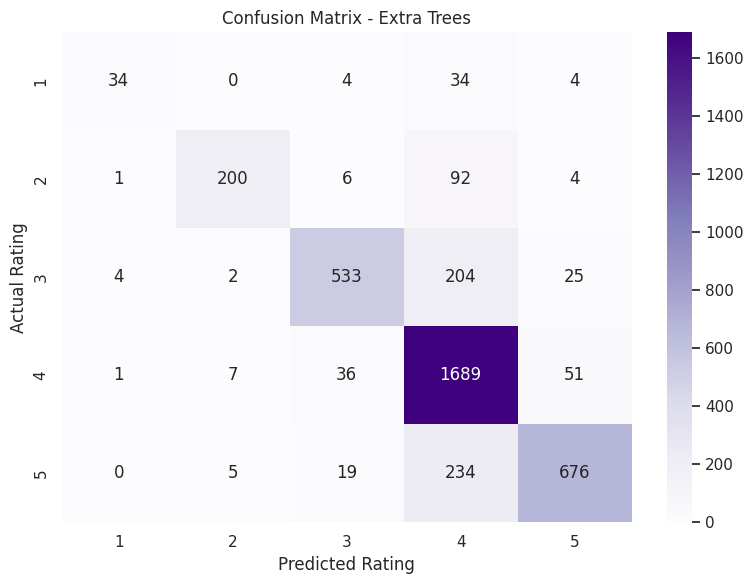

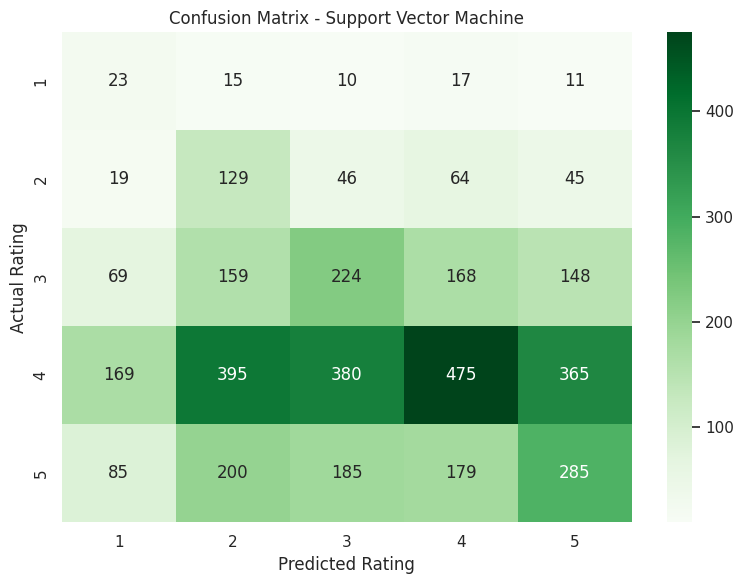


BEST MODEL BASED ON WEIGHTED F1 SCORE
Best Model: Extra Trees
Weighted F1 Score: 0.8063

Classification Report:
              precision    recall  f1-score   support

           1       0.85      0.45      0.59        76
           2       0.93      0.66      0.77       303
           3       0.89      0.69      0.78       768
           4       0.75      0.95      0.84      1784
           5       0.89      0.72      0.80       934

    accuracy                           0.81      3865
   macro avg       0.86      0.69      0.76      3865
weighted avg       0.83      0.81      0.81      3865



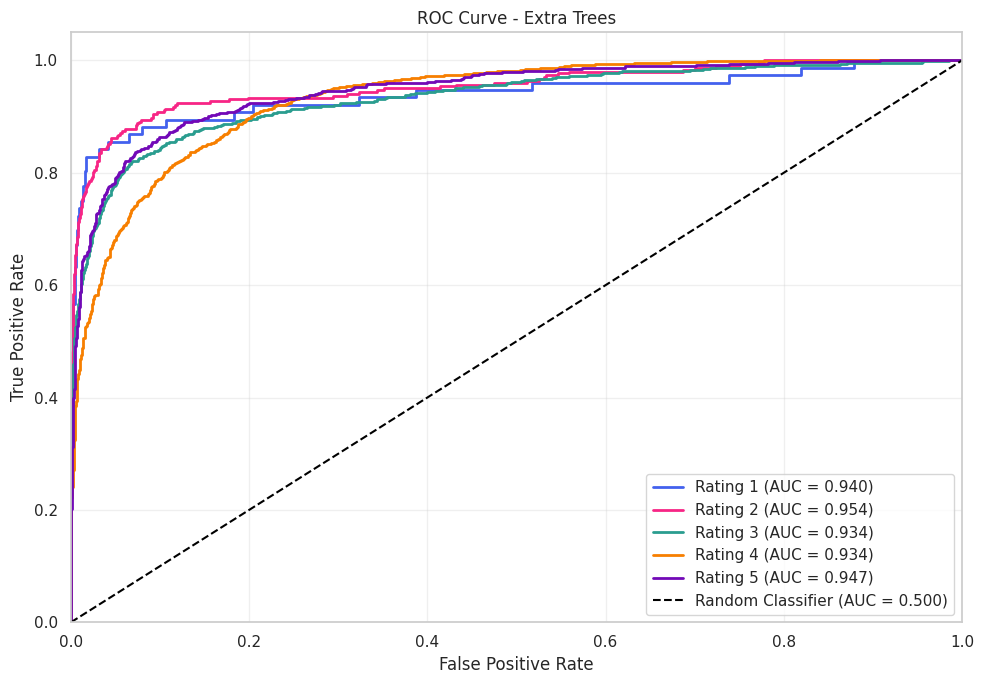

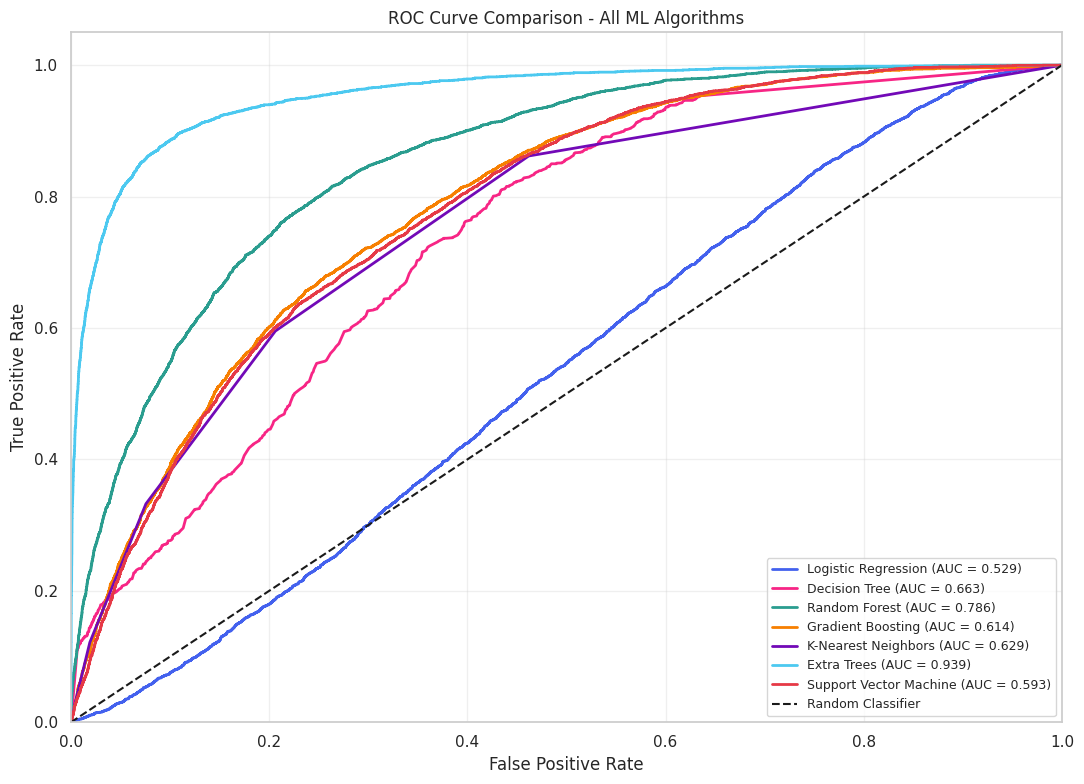

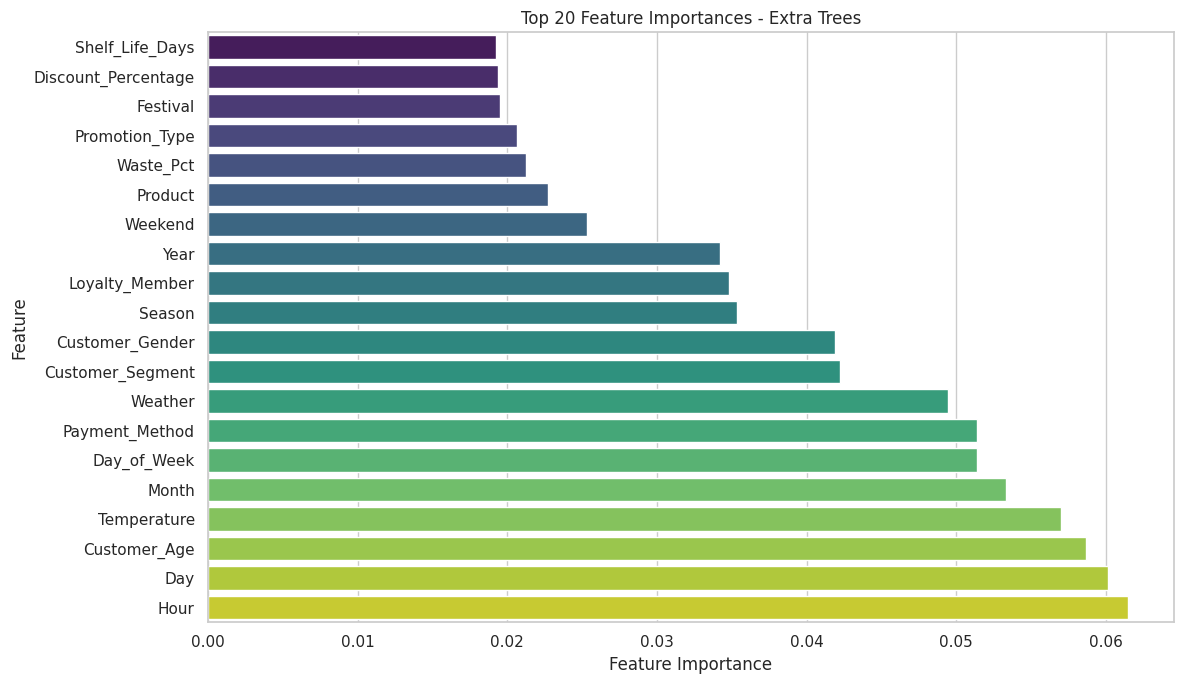


Top Important Features:


,Feature,Importance
0,Hour,0.0615
1,Day,0.0602
2,Customer_Age,0.0587
3,Temperature,0.0570
4,Month,0.0533
5,Day_of_Week,0.0514
6,Payment_Method,0.0514
7,Weather,0.0494
8,Customer_Segment,0.0423
9,Customer_Gender,0.0419



MACHINE LEARNING PIPELINE COMPLETED
Target: Customer_Rating
Training Samples: 15456
Testing Samples: 3865
Input Features: 34
Rating Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Models Successfully Trained: 7

Best Model: Extra Trees
Accuracy: 0.8103
Weighted Precision: 0.8281
Weighted Recall: 0.8103
Weighted F1 Score: 0.8063
ROC AUC: 0.9385

All applicable metrics and ROC visualizations are complete.


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    auc
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "Customer_Rating"

sns.set_theme(style="whitegrid", context="notebook")

COLORS = [
    "#4361EE", "#F72585", "#2A9D8F", "#F77F00",
    "#7209B7", "#4CC9F0", "#E63946", "#8338EC"
]

# ------------------------------------------------
# 2. VALIDATE AND COPY DATA
# ------------------------------------------------

if "df" not in globals():
    raise NameError("Load your dataset into a DataFrame named df first.")

data = df.copy()

if TARGET not in data.columns:
    raise ValueError(f"Target column '{TARGET}' is missing.")

if data.empty:
    raise ValueError("The dataset is empty.")

print("=" * 75)
print("RETAIL CUSTOMER RATING - MACHINE LEARNING")
print("=" * 75)

print("\nOriginal Dataset Shape:", data.shape)
print("\nTarget Column:", TARGET)

# Convert target to numeric so rating values are handled consistently
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")

# Remove rows without a valid target
data = data.dropna(subset=[TARGET]).copy()

# Remove infinite target values, if any
data = data[np.isfinite(data[TARGET])].copy()

# Do not fabricate target labels
if data[TARGET].nunique() < 2:
    raise ValueError(
        "Customer_Rating has fewer than 2 classes. "
        "A classification model requires at least 2 real target classes."
    )

# If the target is effectively continuous, do not arbitrarily convert
# it into classification labels.
if data[TARGET].nunique() > 15:
    raise ValueError(
        "Customer_Rating contains more than 15 unique values and may be "
        "continuous. Use a regression model, or explicitly define meaningful "
        "rating categories based on the dataset's actual rating scale."
    )

print("Rows with valid ratings:", len(data))
print("Observed rating classes:", sorted(data[TARGET].unique()))

print("\nTarget Class Distribution:")
print(data[TARGET].value_counts().sort_index())

# ------------------------------------------------
# 3. DEFINE FEATURES AND TARGET
# ------------------------------------------------

# Exclude the target and high-cardinality identifiers.
# Exclude raw Date/Time columns because calendar features such as
# Year, Month, Day and Hour already exist in the provided dataset.

drop_cols = [
    TARGET,
    "Order_ID",
    "Customer_ID",
    "Store_ID",
    "Date",
    "Time"
]

X = data.drop(
    columns=[c for c in drop_cols if c in data.columns]
).copy()

y_raw = data[TARGET].copy()

# Convert booleans to text so they are encoded consistently
for col in X.columns:
    if pd.api.types.is_bool_dtype(X[col]):
        X[col] = X[col].map({True: "True", False: "False"})

# Convert numeric-looking columns to numeric when appropriate
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        non_missing = X[col].notna().sum()

        if non_missing > 0 and converted.notna().sum() / non_missing >= 0.95:
            X[col] = converted

# Drop columns that contain no usable information
empty_cols = X.columns[X.isna().all()].tolist()
if empty_cols:
    print("\nDropping entirely missing columns:", empty_cols)
    X = X.drop(columns=empty_cols)

constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_cols:
    print("Dropping constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

if X.shape[1] == 0:
    raise ValueError("No usable feature columns remain.")

# Target label encoding: preserves the mapping to original ratings
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_raw)

class_names = target_encoder.classes_
n_classes = len(class_names)

print("\nFeature Matrix Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", n_classes)
print("Rating Label Mapping:")

for encoded_value, original_value in enumerate(class_names):
    print(f"  {original_value} -> {encoded_value}")

# ------------------------------------------------
# 4. TRAIN-TEST SPLIT BEFORE FEATURE ENCODING
# ------------------------------------------------

class_counts = pd.Series(y).value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "At least one rating class has fewer than 2 samples. "
        "A stratified train-test split cannot reliably evaluate every class. "
        "Collect more samples or use a justified alternative split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining Rows:", len(X_train))
print("Testing Rows:", len(X_test))

print("\nTraining Class Distribution:")
print(pd.Series(
    target_encoder.inverse_transform(y_train)
).value_counts().sort_index())

print("\nTesting Class Distribution:")
print(pd.Series(
    target_encoder.inverse_transform(y_test)
).value_counts().sort_index())

# ------------------------------------------------
# 5. LABEL ENCODING OF CATEGORICAL FEATURES
# ------------------------------------------------

# Fit encoders only on the training data.
# Unseen categories in test data receive -1.
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

feature_encoders = {}

for col in categorical_cols:
    train_values = X_train[col].astype("string").fillna("__MISSING__")
    test_values = X_test[col].astype("string").fillna("__MISSING__")

    encoder = LabelEncoder()
    encoder.fit(train_values)

    mapping = {
        label: index
        for index, label in enumerate(encoder.classes_)
    }

    X_train_encoded[col] = train_values.map(mapping).astype(float)
    X_test_encoded[col] = test_values.map(mapping).fillna(-1).astype(float)

    feature_encoders[col] = encoder

# Ensure all feature values are numeric
X_train_encoded = X_train_encoded.apply(
    pd.to_numeric, errors="coerce"
)
X_test_encoded = X_test_encoded.apply(
    pd.to_numeric, errors="coerce"
)

print("\nCategorical Features Label Encoded:", categorical_cols)
print("Numeric Features:", numeric_cols)

if feature_encoders:
    print("\nExample Feature Encoding Mappings:")
    for col, encoder in list(feature_encoders.items())[:5]:
        print(f"\n{col}:")
        print({
            value: index
            for index, value in enumerate(encoder.classes_)
        })

# ------------------------------------------------
# 6. HANDLE MISSING VALUES AND SCALE FEATURES
# ------------------------------------------------

# Imputation and scaling are fitted on training data only.
# Tree models use the same preprocessing for a fair comparison.

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_encoded)
X_test_imputed = imputer.transform(X_test_encoded)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Use scaled values for all models; scaling is particularly important
# for Logistic Regression, KNN and SVM.

print("\nTraining Features Shape:", X_train_scaled.shape)
print("Testing Features Shape:", X_test_scaled.shape)

# ------------------------------------------------
# 7. DEFINE MACHINE LEARNING ALGORITHMS
# ------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=min(5, len(X_train))
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

# ------------------------------------------------
# 8. TRAIN MODELS AND CALCULATE EVALUATION METRICS
# ------------------------------------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}
failed_models = {}

for model_name, model in models.items():

    print("\n" + "-" * 65)
    print("Training:", model_name)

    try:
        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)

        # Align predicted probabilities with all known target classes
        raw_probabilities = model.predict_proba(X_test_scaled)
        aligned_probabilities = np.zeros((len(y_test), n_classes))

        for index, model_class in enumerate(model.classes_):
            aligned_probabilities[:, int(model_class)] = (
                raw_probabilities[:, index]
            )

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )

        # ROC AUC supports binary and multiclass classification.
        if n_classes == 2:
            roc_auc = roc_auc_score(
                y_test, aligned_probabilities[:, 1]
            )
        else:
            roc_auc = roc_auc_score(
                y_test,
                aligned_probabilities,
                multi_class="ovr",
                average="weighted",
                labels=np.arange(n_classes)
            )

        trained_models[model_name] = model
        predictions[model_name] = y_pred
        probabilities[model_name] = aligned_probabilities

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision_Weighted": precision,
            "Recall_Weighted": recall,
            "F1_Weighted": f1,
            "ROC_AUC": roc_auc
        })

        print(f"Accuracy : {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1 Score : {f1:.4f}")
        print(f"ROC AUC  : {roc_auc:.4f}")

    except Exception as error:
        failed_models[model_name] = str(error)
        print("Model skipped due to error:", error)

if not results:
    raise RuntimeError(
        "All models failed. Check target class counts, missing data, "
        "and feature values."
    )

# ------------------------------------------------
# 9. MODEL COMPARISON TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    by="F1_Weighted",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(results_df.round(4))

# ------------------------------------------------
# 10. VISUALIZE MODEL METRICS
# ------------------------------------------------

metric_columns = [
    "Accuracy", "Precision_Weighted",
    "Recall_Weighted", "F1_Weighted", "ROC_AUC"
]

results_long = results_df.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. CONFUSION MATRICES FOR ALL MODELS
# ------------------------------------------------

for index, model_name in enumerate(trained_models):

    cm = confusion_matrix(
        y_test,
        predictions[model_name],
        labels=np.arange(n_classes)
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=["Blues", "Purples", "Greens", "Oranges"][
            index % 4
        ],
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Rating")
    plt.ylabel("Actual Rating")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 12. CLASSIFICATION REPORT FOR BEST MODEL
# ------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]
best_probabilities = probabilities[best_model_name]

print("\n" + "=" * 75)
print("BEST MODEL BASED ON WEIGHTED F1 SCORE")
print("=" * 75)

print("Best Model:", best_model_name)
print(
    "Weighted F1 Score:",
    round(results_df.iloc[0]["F1_Weighted"], 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(n_classes),
        target_names=[str(c) for c in class_names],
        zero_division=0
    )
)

# ------------------------------------------------
# 13. ROC CURVE FOR THE BEST MODEL
# ------------------------------------------------

plt.figure(figsize=(10, 7))

if n_classes == 2:

    # Binary classification: use probability of positive class
    fpr, tpr, thresholds = roc_curve(
        y_test,
        best_probabilities[:, 1],
        pos_label=1
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        color="#4361EE",
        linewidth=2.5,
        label=f"{best_model_name} (AUC = {roc_auc:.3f})"
    )

else:

    # Multiclass ROC: one-vs-rest curve for each rating class
    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(n_classes)
    )

    for class_index in range(n_classes):

        # ROC cannot be computed if a class is absent in the test split
        if len(np.unique(y_test_binary[:, class_index])) < 2:
            print(
                f"Skipping ROC for class {class_names[class_index]}: "
                "the test split does not contain both binary outcomes."
            )
            continue

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, class_index],
            best_probabilities[:, class_index]
        )

        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr,
            linewidth=2,
            color=COLORS[class_index % len(COLORS)],
            label=f"Rating {class_names[class_index]} "
                  f"(AUC = {class_auc:.3f})"
        )

# Random-classifier baseline
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)

plt.title(f"ROC Curve - {best_model_name}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 14. ROC CURVES FOR ALL MODELS
# ------------------------------------------------

plt.figure(figsize=(11, 8))

for index, model_name in enumerate(trained_models):

    model_probabilities = probabilities[model_name]

    try:
        if n_classes == 2:

            fpr, tpr, _ = roc_curve(
                y_test,
                model_probabilities[:, 1],
                pos_label=1
            )

            model_auc = auc(fpr, tpr)

        else:

            y_test_binary = label_binarize(
                y_test,
                classes=np.arange(n_classes)
            )

            # Compute weighted one-vs-rest ROC AUC for the model.
            model_auc = roc_auc_score(
                y_test,
                model_probabilities,
                multi_class="ovr",
                average="weighted",
                labels=np.arange(n_classes)
            )

            # Plot the micro-average ROC curve
            fpr, tpr, _ = roc_curve(
                y_test_binary.ravel(),
                model_probabilities.ravel()
            )

        plt.plot(
            fpr, tpr,
            linewidth=2,
            color=COLORS[index % len(COLORS)],
            label=f"{model_name} (AUC = {model_auc:.3f})"
        )

    except Exception as error:
        print(f"ROC skipped for {model_name}: {error}")

plt.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.title("ROC Curve Comparison - All ML Algorithms")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 15. FEATURE IMPORTANCE
# ------------------------------------------------

if hasattr(best_model, "feature_importances_"):

    importances = best_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": X_train_encoded.columns,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(20)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=importance_df.sort_values("Importance"),
        x="Importance",
        y="Feature",
        hue="Feature",
        palette="viridis",
        legend=False
    )

    plt.title(f"Top 20 Feature Importances - {best_model_name}")
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    print("\nTop Important Features:")
    display(importance_df.reset_index(drop=True).round(4))

elif hasattr(best_model, "coef_"):

    coefficients = np.mean(
        np.abs(best_model.coef_),
        axis=0
    )

    coefficient_df = pd.DataFrame({
        "Feature": X_train_encoded.columns,
        "Absolute_Coefficient": coefficients
    }).sort_values(
        "Absolute_Coefficient",
        ascending=False
    ).head(20)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=coefficient_df.sort_values("Absolute_Coefficient"),
        x="Absolute_Coefficient",
        y="Feature",
        hue="Feature",
        palette="magma",
        legend=False
    )

    plt.title(f"Top Feature Coefficients - {best_model_name}")
    plt.tight_layout()
    plt.show()

    print("\nTop Features by Absolute Coefficient:")
    display(coefficient_df.reset_index(drop=True).round(4))

else:
    print(
        "\nDirect feature importance is not available for this model. "
        "Permutation importance can be used for model-independent analysis."
    )

# ------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("MACHINE LEARNING PIPELINE COMPLETED")
print("=" * 75)

print("Target:", TARGET)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Input Features:", X_train_encoded.shape[1])
print("Rating Classes:", list(class_names))
print("Models Successfully Trained:", len(trained_models))

print("\nBest Model:", best_model_name)

print(
    "Accuracy:",
    round(results_df.iloc[0]["Accuracy"], 4)
)

print(
    "Weighted Precision:",
    round(results_df.iloc[0]["Precision_Weighted"], 4)
)

print(
    "Weighted Recall:",
    round(results_df.iloc[0]["Recall_Weighted"], 4)
)

print(
    "Weighted F1 Score:",
    round(results_df.iloc[0]["F1_Weighted"], 4)
)

print(
    "ROC AUC:",
    round(results_df.iloc[0]["ROC_AUC"], 4)
)

if failed_models:
    print("\nModels That Could Not Be Trained:")
    for model_name, reason in failed_models.items():
        print(f"- {model_name}: {reason}")

print("\nAll applicable metrics and ROC visualizations are complete.")


## Thank you..pls upvote!!!!